# Reliable classification of student posts with DeBERTa

This experiment prioritizes classification reliability, errors and manual review alongside Precision, Recall and F1.
It trains one DeBERTa-v3-base encoder on the real UPenn and Stanford fit partitions. The source contributions are balanced
in the loss. Calibration and validation rows never participate in gradient training. Historical test sets remain separate.

Three datasets are organized under `Project/Datasets`: UPenn, Stanford and CustomForum.
The 160 custom examples are **assistant-authored synthetic drafts**, not real student records or verified gold labels.
They are excluded from training by default. An approved-custom training ablation requires reviewed labels and keeps related scenarios together.

On Kaggle, enable Internet and GPU T4 ×2. The trainer uses one T4 with FP16 plus gradient scaling.
No API key or separately uploaded dataset is needed for the default real-only run.
The historical test sets were inspected previously, so results are exploratory. A better model does not guarantee correct classification of arbitrary text.


In [1]:
import os,sys,json,subprocess,importlib.util
from pathlib import Path
from IPython.display import display,Image,Markdown
IS_KAGGLE=Path('/kaggle/working').exists()
PROJECT=Path(os.environ.get('FORUM_PROJECT_DIR','/kaggle/working/Project' if IS_KAGGLE else str(Path.cwd()/'Project'))).resolve()
for folder in ['scripts','models','reports/reliability','reports/figures','.cache/tmp']:(PROJECT/folder).mkdir(parents=True,exist_ok=True)
os.environ.update(PROJECT_ROOT=str(PROJECT),HF_HOME=str(PROJECT/'.cache/huggingface'),
    HF_HUB_CACHE=str(PROJECT/'.cache/huggingface/hub'),HF_XET_CACHE=str(PROJECT/'.cache/huggingface/xet'),
    HF_HUB_DISABLE_XET='1',HF_HUB_DISABLE_TELEMETRY='1',MPLCONFIGDIR=str(PROJECT/'.cache/matplotlib'),
    TMPDIR=str(PROJECT/'.cache/tmp'),PIP_CACHE_DIR=str(PROJECT/'.cache/pip'),
    OMP_NUM_THREADS='1',OPENBLAS_NUM_THREADS='1',MKL_NUM_THREADS='1',TOKENIZERS_PARALLELISM='false',PYTORCH_ENABLE_MPS_FALLBACK='1')
RUN_TRAINING=os.environ.get('FORUM_REUSE_RELIABILITY','0')!='1'
MAX_EPOCHS=3
PATIENCE=2
MAX_LENGTH=512
USE_APPROVED_CUSTOM=False
RUN_NAME='deberta_reviewed_custom' if USE_APPROVED_CUSTOM else 'deberta_real_only'
RUN_DIR=PROJECT/'reports/reliability'/RUN_NAME
FIGURE_NAME='deberta_reviewed_custom_calibration.png' if USE_APPROVED_CUSTOM else 'deberta_calibration.png' 
print('Project:',PROJECT,'Train:',RUN_TRAINING,'Approved custom ablation:',USE_APPROVED_CUSTOM)


Project: /Users/nhaterik/lastyear/machine/Project Train: False Approved custom ablation: False


## Dependencies and device

Existing PyTorch is retained. Tokenizer dependencies are pinned to a compatible pair.


In [2]:
from importlib.metadata import version,PackageNotFoundError
required={'torch':'torch>=2.8','transformers':'transformers>=4.55,<6','sklearn':'scikit-learn>=1.6,<2',
          'numpy':'numpy','matplotlib':'matplotlib','joblib':'joblib','sentencepiece':'sentencepiece==0.2.1','google.protobuf':'protobuf==6.33.6'}
packages=[]
for module,spec in required.items():
    try:available=importlib.util.find_spec(module) is not None
    except ModuleNotFoundError:available=False
    if not available:packages.append(spec)
for package,expected in [('sentencepiece','0.2.1'),('protobuf','6.33.6')]:
    try:installed=version(package)
    except PackageNotFoundError:installed=None
    if installed!=expected and f'{package}=={expected}' not in packages:packages.append(f'{package}=={expected}')
if packages:subprocess.run([sys.executable,'-m','pip','install',*packages],check=True)
import torch,transformers,sklearn,numpy as np
DEVICE='cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
if IS_KAGGLE and RUN_TRAINING and DEVICE!='cuda':raise RuntimeError('Enable a Kaggle GPU before full training.')
BATCH_SIZE=8 if DEVICE=='cuda' else 4
ACCUMULATION=4 if DEVICE=='cuda' else 8
print({'python':sys.version,'torch':torch.__version__,'transformers':transformers.__version__,
       'sklearn':sklearn.__version__,'device':DEVICE,'batch_size':BATCH_SIZE,'accumulation':ACCUMULATION})


/Users/nhaterik/lastyear/machine/Project/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'python': '3.12.13 (main, Mar  3 2026, 12:39:30) [Clang 21.0.0 (clang-2100.0.123.102)]', 'torch': '2.15.0', 'transformers': '4.57.6', 'sklearn': '1.9.1', 'device': 'mps', 'batch_size': 4, 'accumulation': 8}


## Source prepare_data.py


In [3]:
(PROJECT/"scripts"/'prepare_data.py').write_text(r'''"""Download and audit two pinned public datasets using only Python's standard library."""
from __future__ import annotations

import argparse
import csv
import hashlib
import html
import json
import math
import re
import subprocess
import unicodedata
from collections import Counter, defaultdict
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
REVISION = "ebf3695f01d2dec197253eb89499f4835bb7d0fa"
FILES = {"upenn": "All_Courses_REDACTED_CODED.csv", "stanford": "Stanford.csv"}
EXPECTED_SHA256 = {
    "upenn": "403301d079abcea1acc318b7a63f766658350dbc0e85eead79f7befc65aa48c3",
    "stanford": "31e8885939604a20cd0a903d1e5ebca811b850530b8e9ed5169e1936628142f2",
}
FIELDS = ["post_id", "source", "source_row", "source_id", "source_time", "source_course_type", "text_raw",
          "text_clean", "urgency", "priority", "word_count", "text_sha256"]
TAG = re.compile(r"</?(?:p|br|div|span|a|b|i|strong|em|ul|ol|li|blockquote|pre|code|hr)(?:\s[^<>]*?)?\s*/?>", re.I)


def sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()


def dump_json(path: Path, data) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(data, ensure_ascii=False, indent=2, sort_keys=True) + "\n", encoding="utf-8")


def clean_text(text: str) -> str:
    return " ".join(TAG.sub(" ", unicodedata.normalize("NFC", html.unescape(text))).split())


def percentile(values, fraction):
    ordered = sorted(values)
    index = (len(ordered) - 1) * fraction
    low = math.floor(index)
    high = math.ceil(index)
    return round(ordered[low] + (ordered[high] - ordered[low]) * (index - low), 2)


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--download", action="store_true", help="Download missing raw files, never replace existing files")
    args = parser.parse_args()
    rejected, datasets, audit = [], {}, {"source_revision": REVISION, "label_rule": "priority = int(urgency > 4)", "datasets": {}}
    for source, filename in FILES.items():
        path = ROOT / "data/raw" / filename
        url = f"https://raw.githubusercontent.com/pcla-code/forum-posts-urgency/{REVISION}/{filename}"
        path.parent.mkdir(parents=True, exist_ok=True)
        if not path.exists():
            if not args.download:
                raise SystemExit(f"Thiếu {path.name}. Chạy bash Project/run.sh --download từ machine.")
            print(f"Đang tải {source} từ commit {REVISION[:12]}...", flush=True)
            temporary = path.with_suffix(".csv.part")
            try:
                subprocess.run(["curl", "-q", "--fail", "--location", "--silent", "--show-error",
                                "--connect-timeout", "10", "--max-time", "120", "--retry", "1",
                                "--output", str(temporary), url], check=True)
                temporary.replace(path)
            finally:
                temporary.unlink(missing_ok=True)
        if sha256(path) != EXPECTED_SHA256[source]:
            raise ValueError(f"SHA-256 tệp gốc không khớp phiên bản cố định: {filename}")
        groups = defaultdict(list)
        counts = Counter()
        with path.open(encoding="utf-8-sig", newline="") as handle:
            reader = csv.DictReader(handle)
            if not {"post_text", "Urgency_1_7"}.issubset(reader.fieldnames or []):
                raise ValueError(f"Schema không phù hợp: {path.name}")
            columns = reader.fieldnames
            for row_number, raw in enumerate(reader, start=2):
                counts["raw_rows"] += 1
                reason = None
                if None in raw or raw.get("post_text") is None or raw.get("Urgency_1_7") is None:
                    reason = "malformed_or_missing_fields"
                try:
                    urgency = float(raw.get("Urgency_1_7") or "nan")
                except (TypeError, ValueError):
                    urgency = float("nan")
                if reason is None and (not math.isfinite(urgency) or not 1 <= urgency <= 7):
                    reason = "missing_or_invalid_urgency"
                text = clean_text(raw.get("post_text") or "")
                if reason is None and not text:
                    reason = "empty_text"
                if reason:
                    counts[reason] += 1
                    rejected.append({"source": source, "source_row": row_number, "reason": reason})
                    continue
                counts["valid_rows"] += 1
                key = hashlib.sha256(text.casefold().encode("utf-8")).hexdigest()
                groups[key].append({"post_id": f"{source}_{row_number:06d}", "source": source,
                                    "source_row": row_number, "source_id": raw.get("id", ""),
                                    "source_time": raw.get("post_time", ""),
                                    "source_course_type": raw.get("CourseType", ""), "text_raw": raw["post_text"],
                                    "text_clean": text, "urgency": urgency, "priority": int(urgency > 4),
                                    "word_count": len(text.split()), "text_sha256": key})
        retained = []
        for rows in groups.values():
            conflict = len({row["priority"] for row in rows}) > 1
            if conflict:
                counts["conflicting_groups"] += 1
            discarded = rows if conflict else rows[1:]
            reason = "conflicting_binary_labels" if conflict else "duplicate_within_source"
            counts[reason] += len(discarded)
            rejected.extend({"source": source, "source_row": row["source_row"], "reason": reason} for row in discarded)
            if not conflict:
                retained.append(rows[0])
        counts["after_within_source_dedup"] = len(retained)
        counts["cross_source_duplicates"] = 0
        datasets[source] = sorted(retained, key=lambda row: row["source_row"])
        audit["datasets"][source] = {"raw_file": str(path.relative_to(ROOT)), "url": url,
                                       "raw_sha256": sha256(path), "raw_bytes": path.stat().st_size,
                                       "columns": columns, "counts": dict(counts)}

    upenn_keys = {row["text_sha256"] for row in datasets["upenn"]}
    unique_stanford = []
    for row in datasets["stanford"]:
        if row["text_sha256"] in upenn_keys:
            audit["datasets"]["stanford"]["counts"]["cross_source_duplicates"] += 1
            rejected.append({"source": "stanford", "source_row": row["source_row"], "reason": "duplicate_across_sources"})
        else:
            unique_stanford.append(row)
    datasets["stanford"] = unique_stanford

    for source, rows in datasets.items():
        if not rows:
            raise ValueError(f"Không có dữ liệu hợp lệ: {source}")
        target = ROOT / "data/processed" / f"{source}.csv"
        target.parent.mkdir(parents=True, exist_ok=True)
        with target.open("w", encoding="utf-8", newline="") as handle:
            writer = csv.DictWriter(handle, fieldnames=FIELDS)
            writer.writeheader()
            writer.writerows(rows)
        item = audit["datasets"][source]
        item["counts"]["final_rows"] = len(rows)
        item["label_counts"] = dict(Counter(str(row["priority"]) for row in rows))
        item["urgency_counts"] = dict(Counter(str(row["urgency"]) for row in rows))
        lengths = [row["word_count"] for row in rows]
        item["word_lengths"] = {"min": min(lengths), "median": percentile(lengths, .5),
                                 "p95": percentile(lengths, .95), "max": max(lengths),
                                 "mean": round(sum(lengths) / len(lengths), 2)}
        bounds = [(0, 25), (25, 50), (50, 100), (100, 200), (200, 400), (400, None)]
        item["length_histogram"] = {f"{lower + 1}–{upper}" if upper else f">{lower}":
            sum(length > lower and (upper is None or length <= upper) for length in lengths)
            for lower, upper in bounds}
        item["processed_file"] = str(target.relative_to(ROOT))
        item["processed_sha256"] = sha256(target)
        n_rejected = sum(record["source"] == source for record in rejected)
        assert item["counts"]["raw_rows"] == len(rows) + n_rejected
        assert all(row["text_clean"].strip() for row in rows)
        assert all(math.isfinite(row["urgency"]) and 1 <= row["urgency"] <= 7 for row in rows)
        assert all(row["priority"] == int(row["urgency"] > 4) for row in rows)
        assert len({row["text_sha256"] for row in rows}) == len(rows)
        assert {row["priority"] for row in rows} == {0, 1}
        print(f"{source}: raw={item['counts']['raw_rows']}, final={len(rows)}, priority={item['label_counts'].get('1', 0)}", flush=True)
    assert not ({row["text_sha256"] for row in datasets["upenn"]} &
                {row["text_sha256"] for row in datasets["stanford"]})
    audit["checks"] = {"rows_accounted_for": True, "nonempty_text": True, "labels_in_range": True,
                        "both_binary_classes_present": True, "no_exact_duplicates_within_sources": True,
                        "no_exact_duplicates_between_sources": True}
    dump_json(ROOT / "reports/data_audit.json", audit)
    with (ROOT / "reports/rejected_rows.csv").open("w", encoding="utf-8", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=["source", "source_row", "reason"])
        writer.writeheader()
        writer.writerows(sorted(rejected, key=lambda row: (row["source"], row["source_row"])))


if __name__ == "__main__":
    main()
''',encoding="utf-8")


9552

## Source train.py


In [4]:
(PROJECT/"scripts"/'train.py').write_text(r'''"""Reproducible source-only model selection and two-source held-out evaluation."""
from __future__ import annotations
import csv
import hashlib
import json
import platform
import sys
import time
from pathlib import Path
import joblib
import numpy as np
import sklearn
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score, precision_recall_curve)
from sklearn.model_selection import (GroupShuffleSplit, StratifiedKFold, StratifiedGroupKFold,
    train_test_split, GridSearchCV, cross_val_predict)
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from prepare_data import dump_json, sha256

ROOT=Path(__file__).resolve().parents[1]
OUT=ROOT/'reports/experiments'
SEED=42
ENCODER='sentence-transformers/all-MiniLM-L6-v2'
ENCODER_REV='1110a243fdf4706b3f48f1d95db1a4f5529b4d41'

def read_csv(path):
    with path.open(encoding='utf-8',newline='') as f:
        return list(csv.DictReader(f))

def write_csv(path, rows):
    path.parent.mkdir(parents=True,exist_ok=True)
    with path.open('w',encoding='utf-8',newline='') as f:
        writer=csv.DictWriter(f,fieldnames=list(rows[0]))
        writer.writeheader();writer.writerows(rows)

def scores(model,x):
    if hasattr(model,'predict_proba'):
        return model.predict_proba(x)[:,1]
    return model.decision_function(x)

def metrics(y,s,t,ids):
    p=np.asarray(s)>=t
    matrix=confusion_matrix(y,p,labels=[0,1])
    order=np.lexsort((np.asarray(ids),-np.asarray(s)))
    k=min(20,len(y));found=int(np.asarray(y)[order[:k]].sum())
    return dict(precision=float(precision_score(y,p,zero_division=0)),recall=float(recall_score(y,p,zero_division=0)),
        f1=float(f1_score(y,p,zero_division=0)),macro_f1=float(f1_score(y,p,average='macro')),
        accuracy=float(accuracy_score(y,p)),average_precision=float(average_precision_score(y,s)),
        roc_auc=float(roc_auc_score(y,s)),precision_at_20=found/k,recall_at_20=found/int(np.sum(y)),
        top20_found=found,confusion_matrix=matrix.tolist(),test_size=len(y),positive_count=int(np.sum(y)))

def tune_threshold(y,s):
    precision,recall,thresholds=precision_recall_curve(y,s)
    f=2*precision[:-1]*recall[:-1]/np.maximum(precision[:-1]+recall[:-1],1e-12)
    # Highest threshold among exact F1 ties; no target test labels are used.
    index=np.flatnonzero(np.isclose(f,np.max(f),atol=1e-12,rtol=0))[-1]
    return float(thresholds[index]),float(f[index])

def embeddings(data):
    import torch
    from sentence_transformers import SentenceTransformer
    from huggingface_hub import snapshot_download
    snapshot=snapshot_download(ENCODER,revision=ENCODER_REV,
        allow_patterns=['*.json','*.txt','*.safetensors','1_Pooling/*'])
    device='cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
    torch.manual_seed(SEED)
    encoder=SentenceTransformer(snapshot,device=device)
    result={};info={'model':ENCODER,'revision':ENCODER_REV,'device':device,
        'snapshot':str(Path(snapshot).relative_to(ROOT)),'max_seq_length':encoder.max_seq_length,
        'dimension':(encoder.get_embedding_dimension() if hasattr(encoder,'get_embedding_dimension')
                     else encoder.get_sentence_embedding_dimension()),'sources':{}}
    for source,rows in data.items():
        path=ROOT/'.cache/embeddings'/f'{source}.npz';path.parent.mkdir(parents=True,exist_ok=True)
        fingerprint=sha256(ROOT/f'data/processed/{source}.csv')
        if path.exists():
            cached=np.load(path)
            if str(cached['fingerprint'])==fingerprint and str(cached['revision'])==ENCODER_REV:
                result[source]=cached['vectors'];info['sources'][source]={'cache_used':True};continue
        texts=[row['text_clean'] for row in rows]
        start=time.perf_counter()
        lengths=[]
        for i in range(0,len(texts),128):
            batch=encoder.tokenizer(texts[i:i+128],truncation=False,add_special_tokens=True)['input_ids']
            lengths.extend(map(len,batch))
        vectors=encoder.encode(texts,batch_size=64,normalize_embeddings=True,show_progress_bar=True).astype(np.float32)
        elapsed=time.perf_counter()-start
        np.savez_compressed(path,vectors=vectors,fingerprint=fingerprint,revision=ENCODER_REV)
        result[source]=vectors
        info['sources'][source]={'cache_used':False,'encoding_seconds':elapsed,
            'truncated_posts':sum(n>encoder.max_seq_length for n in lengths),'total':len(texts),
            'tokens_p95':float(np.percentile(lengths,95)),'tokens_max':max(lengths)}
        dump_json(OUT/'encoder_info.json',info)
    # Preserve original measured token/encoding stats when embeddings are reused.
    if (OUT/'encoder_info.json').exists():
        previous=json.loads((OUT/'encoder_info.json').read_text())
        for source,entry in info['sources'].items():
            if entry.get('cache_used') and source in previous.get('sources',{}):
                info['sources'][source]=previous['sources'][source]
    dump_json(OUT/'encoder_info.json',info)
    return result,info

def main():
    OUT.mkdir(parents=True,exist_ok=True)
    (ROOT/'models').mkdir(exist_ok=True)
    data={source:read_csv(ROOT/f'data/processed/{source}.csv') for source in ['upenn','stanford']}
    splits={};folds={};split_rows=[];split_info={}
    for source,rows in data.items():
        y=np.array([int(row['priority']) for row in rows]);indices=np.arange(len(rows))
        if source=='upenn':
            groups=np.array([row['source_id'] for row in rows])
            assert all(groups)
            train,test=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED).split(indices,y,groups))
            folds[source]=list(StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=SEED).split(train,y[train],groups[train]))
            assert not (set(groups[train]) & set(groups[test]))
            policy='GroupShuffleSplit by UPenn student id; 3-fold StratifiedGroupKFold for tuning'
        else:
            train,test=train_test_split(indices,test_size=.2,random_state=SEED,stratify=y)
            folds[source]=list(StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED).split(train,y[train]))
            policy='Stratified hold-out and 3-fold StratifiedKFold; author/thread IDs unavailable'
        for a,b in folds[source]:
            assert len(set(y[train[a]]))==2 and len(set(y[train[b]]))==2
        splits[source]=(train,test)
        split_info[source]={'policy':policy,'train':len(train),'test':len(test),
            'train_positives':int(y[train].sum()),'test_positives':int(y[test].sum()),
            'processed_sha256':sha256(ROOT/f'data/processed/{source}.csv')}
        train_set=set(train)
        assignments={int(i):('train' if i in train_set else 'test') for i in indices}
        split_rows.extend({'source':source,'post_id':row['post_id'],'split':assignments[i]} for i,row in enumerate(rows))
    write_csv(OUT/'split_ids.csv',split_rows);dump_json(OUT/'split_info.json',split_info)
    dump_json(OUT/'config.json',{'seed':SEED,'folds':3,'test_fraction':.2,'tfidf':{
        'ngram_range':[1,2],'min_df':2,'max_df':.98,'max_features':40000,'sublinear_tf':True},
        'threshold_rule':'Maximize positive F1 on source-only out-of-fold predictions; ties use largest threshold',
        'deployment_rule':'Best tuned OOF F1 among Stanford-trained models; independent test scores not used',
        'encoder_revision':ENCODER_REV,'data_hashes':{s:i['processed_sha256'] for s,i in split_info.items()}})
    results=[];cv_records=[]
    # Train TF-IDF first, so useful artifacts exist before downloading the optional encoder.
    embedded=None;encoder_info=None
    for representation in ['tfidf','minilm']:
        if representation=='minilm':
            embedded,encoder_info=embeddings(data)
        for source,rows in data.items():
            train,_=splits[source]
            y=np.array([int(row['priority']) for row in rows]);texts=np.array([row['text_clean'] for row in rows],dtype=object)
            x=texts if representation=='tfidf' else embedded[source]
            if representation=='tfidf':
                candidates=[('logreg',LogisticRegression(class_weight='balanced',solver='liblinear',max_iter=2000,random_state=SEED),{'classifier__C':[.3,1.,3.]}),
                    ('svm',LinearSVC(class_weight='balanced',max_iter=10000,random_state=SEED),{'classifier__C':[.3,1.,3.]}),
                    ('nb',MultinomialNB(),{'classifier__alpha':[.1,.5,1.]}),
                    ('dummy',DummyClassifier(strategy='prior'),{})]
            else:
                candidates=[('logreg',LogisticRegression(class_weight='balanced',solver='liblinear',max_iter=2000,random_state=SEED),{'C':[.3,1.,3.,10.]})]
            for name,classifier,grid in candidates:
                slug=f'{representation}_{name}'
                print(f'TRAIN {source} / {slug}',flush=True)
                if representation=='tfidf':
                    model=Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),min_df=2,max_df=.98,max_features=40000,
                        sublinear_tf=True,strip_accents='unicode',dtype=np.float32)),('classifier',classifier)])
                else:model=classifier
                start=time.perf_counter()
                search=GridSearchCV(model,grid,cv=folds[source],scoring='f1',n_jobs=1,refit=True,return_train_score=False)
                search.fit(x[train],y[train]);model=search.best_estimator_
                method='decision_function' if name=='svm' else 'predict_proba'
                oof=cross_val_predict(clone(model),x[train],y[train],cv=folds[source],method=method,n_jobs=1)
                oof=oof if name=='svm' else oof[:,1]
                default=0. if name=='svm' else .5
                threshold,oof_f1=tune_threshold(y[train],oof)
                if name=='dummy': threshold=default;oof_f1=float(f1_score(y[train],oof>=threshold,zero_division=0))
                elapsed=time.perf_counter()-start
                card={'source':source,'model':slug,'representation':representation,'name':name,
                    'threshold':threshold,'default_threshold':default,'cv_mean_f1':float(search.best_score_),
                    'cv_std_f1':float(search.cv_results_['std_test_score'][search.best_index_]),
                    'oof_tuned_f1':oof_f1,'best_params':search.best_params_,'training_seconds':elapsed}
                if representation=='minilm':card['encoder']=encoder_info
                cv_records.append(card)
                bundle={'model':model,'card':card}
                joblib.dump(bundle,ROOT/'models'/f'{source}__{slug}.joblib',compress=3)
                write_csv(OUT/f'oof_{source}_{slug}.csv',[{'post_id':rows[i]['post_id'],'label':int(y[i]),'score':float(s)} for i,s in zip(train,oof)])
                for target,target_rows in data.items():
                    _,test=splits[target]
                    test_x=np.array([row['text_clean'] for row in target_rows],dtype=object)[test] if representation=='tfidf' else embedded[target][test]
                    test_y=np.array([int(row['priority']) for row in target_rows])[test]
                    ids=[target_rows[i]['post_id'] for i in test]
                    start=time.perf_counter();s=scores(model,test_x);infer_seconds=time.perf_counter()-start
                    record={'train_source':source,'test_source':target,'model':slug,'threshold':threshold,
                        'training_seconds':elapsed,'inference_seconds':infer_seconds,**metrics(test_y,s,threshold,ids)}
                    record['default_threshold_metrics']=metrics(test_y,s,default,ids)
                    results.append(record)
                    prediction_rows=[]
                    for i,label,score in zip(test,test_y,s):
                        row=target_rows[i];pred=int(score>=threshold)
                        prediction_rows.append({'post_id':row['post_id'],'source':target,'source_id':row['source_id'],
                            'course_type':row['source_course_type'],'text':row['text_clean'],'urgency':row['urgency'],
                            'label':int(label),'predicted':pred,'score':float(score),
                            'error':'FN' if label==1 and pred==0 else 'FP' if label==0 and pred==1 else ''})
                    write_csv(OUT/f'predictions_{source}_{target}_{slug}.csv',prediction_rows)
                    print(f'  TEST {target}: P={record["precision"]:.3f} R={record["recall"]:.3f} F1={record["f1"]:.3f}',flush=True)
                dump_json(OUT/'results.json',results);dump_json(OUT/'cv_results.json',cv_records)
    selected=max((r for r in cv_records if r['source']=='stanford' and r['name']!='dummy'),key=lambda r:r['oof_tuned_f1'])
    dump_json(ROOT/'models/deployment.json',{'source':selected['source'],'model':selected['model'],
        'file':f"models/{selected['source']}__{selected['model']}.joblib",'selection_rule':'Stanford source training OOF F1 only',
        'oof_tuned_f1':selected['oof_tuned_f1'],'threshold':selected['threshold']})
    dump_json(OUT/'training_environment.json',{'python':sys.version,'sklearn':sklearn.__version__,
        'numpy':np.__version__,'platform':platform.platform(),'seed':SEED})
    print('DEPLOYMENT',selected['source'],selected['model'],flush=True)

if __name__=='__main__':main()
''',encoding="utf-8")


13597

## Source finetune_minilm.py


In [5]:
(PROJECT/"scripts"/'finetune_minilm.py').write_text(r'''"""Portable supervised MiniLM fine-tuning, source-only selection, CV and offline export."""
from __future__ import annotations
import argparse,csv,gc,hashlib,json,math,os,random,time,sys
from contextlib import nullcontext
from pathlib import Path
import numpy as np
import torch
from sklearn.model_selection import GroupShuffleSplit,StratifiedGroupKFold,StratifiedKFold,train_test_split
from sklearn.metrics import average_precision_score,f1_score
from transformers import AutoTokenizer,AutoModelForSequenceClassification,get_linear_schedule_with_warmup
from train import metrics,tune_threshold,read_csv,write_csv,ENCODER,ENCODER_REV
from prepare_data import dump_json,sha256,clean_text

ROOT=Path(os.environ.get('PROJECT_ROOT',Path(__file__).resolve().parents[1])).resolve()
OUT=ROOT/'reports/fine_tuning'
CONFIGS={
    'plain':{'weighted':False,'augmentation':False,'lr':2e-5},
    'weighted':{'weighted':True,'augmentation':False,'lr':2e-5},
    'weighted_aug':{'weighted':True,'augmentation':True,'lr':2e-5},
}
MIXED_PRECISION=False

def autocast(device):
    return torch.autocast(device_type=device,dtype=torch.bfloat16) if MIXED_PRECISION else nullcontext()
CONTRACTIONS={"can't":"cannot","won't":"will not","don't":"do not","doesn't":"does not",
    "didn't":"did not","isn't":"is not","aren't":"are not","wasn't":"was not","weren't":"were not",
    "couldn't":"could not","wouldn't":"would not","shouldn't":"should not","haven't":"have not",
    "hasn't":"has not","hadn't":"had not","i'm":"I am","you're":"you are","we're":"we are",
    "they're":"they are","i've":"I have","we've":"we have","i'll":"I will","we'll":"we will"}

def augment(text):
    import re
    text=text.replace('’',"'")
    return re.sub(r"\b(?:"+'|'.join(re.escape(k) for k in CONTRACTIONS)+r")\b",
                  lambda m:CONTRACTIONS[m.group(0).lower()],text,flags=re.I)

def seed_all(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)

def snapshot():
    local=ROOT/'.cache/huggingface/hub'/('models--'+ENCODER.replace('/','--'))/'snapshots'/ENCODER_REV
    if local.exists():return str(local)
    from huggingface_hub import snapshot_download
    return snapshot_download(ENCODER,revision=ENCODER_REV,allow_patterns=['*.json','*.txt','*.safetensors','1_Pooling/*'])

def setup():
    OUT.mkdir(parents=True,exist_ok=True)
    device='cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
    tokenizer=AutoTokenizer.from_pretrained(snapshot(),local_files_only=True)
    return device,tokenizer

def batches(encodings,indices,batch_size,shuffle=False,seed=42):
    # Sort by length to reduce padding; shuffle batch order for each training epoch.
    order=sorted(map(int,indices),key=lambda i:len(encodings[i]['input_ids']))
    chunks=[order[i:i+batch_size] for i in range(0,len(order),batch_size)]
    if shuffle:random.Random(seed).shuffle(chunks)
    yield from chunks

def encode(tokenizer,texts,max_length):
    result=[]
    for start in range(0,len(texts),256):
        encoded=tokenizer(texts[start:start+256],truncation=True,max_length=max_length,padding=False)
        result.extend({k:encoded[k][i] for k in encoded} for i in range(len(encoded['input_ids'])))
    return result

def tensor_batch(tokenizer,encoded,idx,device):
    return {k:v.to(device) for k,v in tokenizer.pad([encoded[i] for i in idx],padding=True,return_tensors='pt').items()}

def predict(model,tokenizer,encoded,device,batch_size):
    model.eval();scores=np.empty(len(encoded),dtype=np.float64)
    with torch.inference_mode():
        for idx in batches(encoded,range(len(encoded)),batch_size):
            with autocast(device):
                values=torch.softmax(model(**tensor_batch(tokenizer,encoded,idx,device)).logits.float(),dim=-1)[:,1]
            scores[idx]=values.float().cpu().numpy()
    return scores

def new_model(seed,device):
    seed_all(seed)
    model=AutoModelForSequenceClassification.from_pretrained(snapshot(),num_labels=2,
        id2label={0:'NOT_URGENT',1:'URGENT'},label2id={'NOT_URGENT':0,'URGENT':1},
        attn_implementation='sdpa',local_files_only=True)
    return model.to(device)

def fit_run(source,name,config,train_rows,val_rows,device,tokenizer,args,fixed_epochs=None,export=None):
    directory=OUT/source/name;directory.mkdir(parents=True,exist_ok=True)
    texts=[r['text_clean'] for r in train_rows];labels=[int(r['priority']) for r in train_rows]
    augmented=[]
    if config['augmentation']:
        for r in train_rows:
            changed=augment(r['text_clean'])
            if changed!=r['text_clean']:
                texts.append(changed);labels.append(int(r['priority']))
                augmented.append({'parent_post_id':r['post_id'],'label':r['priority'],'text':changed})
    if augmented:write_csv(directory/'augmented_rows.csv',augmented)
    encoded=encode(tokenizer,texts,args.max_length);y=np.array(labels)
    val_enc=encode(tokenizer,[r['text_clean'] for r in val_rows],args.max_length) if val_rows else []
    val_y=np.array([int(r['priority']) for r in val_rows])
    model=new_model(args.seed,device)
    positive=int(y.sum());negative=len(y)-positive
    weights=torch.tensor([len(y)/(2*negative),len(y)/(2*positive)],dtype=torch.float32,device=device) if config['weighted'] else None
    criterion=torch.nn.CrossEntropyLoss(weight=weights)
    optimizer=torch.optim.AdamW(model.parameters(),lr=config['lr'],weight_decay=.01)
    epochs=fixed_epochs or args.epochs
    steps_per_epoch=math.ceil(len(y)/args.batch_size)
    scheduler=get_linear_schedule_with_warmup(optimizer,num_warmup_steps=max(1,int(steps_per_epoch*epochs*.1)),num_training_steps=steps_per_epoch*epochs)
    best_ap=-1.;best_epoch=0;best_scores=None;stale=0;history=[]
    start=time.perf_counter();checkpoint=directory/'best_state.pt'
    for epoch in range(1,epochs+1):
        model.train();loss_sum=0.;seen=0;epoch_start=time.perf_counter()
        for step,idx in enumerate(batches(encoded,range(len(y)),args.batch_size,True,args.seed+epoch)):
            optimizer.zero_grad(set_to_none=True)
            inputs=tensor_batch(tokenizer,encoded,idx,device)
            target=torch.tensor(y[idx],device=device,dtype=torch.long)
            with autocast(device):
                loss=criterion(model(**inputs).logits,target)
            loss.backward();torch.nn.utils.clip_grad_norm_(model.parameters(),1.)
            optimizer.step();scheduler.step()
            loss_sum+=float(loss.detach().cpu())*len(idx);seen+=len(idx)
        record={'epoch':epoch,'train_loss':loss_sum/seen,'seconds':time.perf_counter()-epoch_start}
        if val_rows:
            scores=predict(model,tokenizer,val_enc,device,args.batch_size*2)
            ap=float(average_precision_score(val_y,scores));threshold,tuned_f1=tune_threshold(val_y,scores)
            record.update(val_ap=ap,val_f1_default=float(f1_score(val_y,scores>=.5,zero_division=0)),
                          val_f1_tuned=tuned_f1,threshold=threshold)
            if ap>best_ap+1e-5:
                best_ap=ap;best_epoch=epoch;best_scores=scores.copy();stale=0
                torch.save({k:v.detach().cpu() for k,v in model.state_dict().items()},checkpoint)
            else:stale+=1
        else:best_epoch=epoch
        history.append(record);dump_json(directory/'history.json',history)
        print(source,name,json.dumps(record),flush=True)
        if val_rows and stale>=args.patience:break
    if val_rows:
        state=torch.load(checkpoint,map_location='cpu',weights_only=True)
        model.load_state_dict(state);del state
        threshold,tuned_f1=tune_threshold(val_y,best_scores)
        write_csv(directory/'validation_predictions.csv',[{'post_id':r['post_id'],'label':int(r['priority']),'score':float(s)} for r,s in zip(val_rows,best_scores)])
    else:threshold=.5;tuned_f1=None
    card={'source':source,'name':name,'config':config,'best_epoch':best_epoch,'epochs_run':len(history),
          'validation_ap':best_ap if val_rows else None,'validation_f1_tuned':tuned_f1,'validation_threshold':threshold,
          'original_training_posts':len(train_rows),'augmented_posts':len(augmented),'training_rows':len(y),
          'validation_rows':len(val_rows),'seconds':time.perf_counter()-start,'device':device,
          'max_length':args.max_length,'batch_size':args.batch_size,'seed':args.seed,'history':history}
    dump_json(directory/'run.json',card)
    if export:
        model.save_pretrained(export,safe_serialization=True);tokenizer.save_pretrained(export)
    checkpoint.unlink(missing_ok=True)
    del optimizer,scheduler,encoded,val_enc
    gc.collect()
    return model,card,best_scores

def release(model,device):
    model.to('cpu')
    del model;gc.collect()
    if device=='mps':torch.mps.empty_cache()
    if device=='cuda':torch.cuda.empty_cache()

def load_data():
    data={s:read_csv(ROOT/f'data/processed/{s}.csv') for s in ['upenn','stanford']}
    assignment={r['post_id']:r['split'] for r in read_csv(ROOT/'reports/experiments/split_ids.csv')}
    training={s:[r for r in rows if assignment[r['post_id']]=='train'] for s,rows in data.items()}
    testing={s:[r for r in rows if assignment[r['post_id']]=='test'] for s,rows in data.items()}
    return data,training,testing

def main():
    global MIXED_PRECISION
    parser=argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--stage',choices=['benchmark','scout','cv','final','all'],default='all')
    parser.add_argument('--sources',nargs='+',choices=['upenn','stanford'],default=['upenn','stanford'])
    parser.add_argument('--epochs',type=int,default=4);parser.add_argument('--patience',type=int,default=2)
    parser.add_argument('--batch-size',type=int,default=64);parser.add_argument('--max-length',type=int,default=256)
    parser.add_argument('--bf16',action='store_true',help='Use bfloat16 autocast on supported MPS/CUDA hardware')
    parser.add_argument('--folds',type=int,default=5);parser.add_argument('--seed',type=int,default=42)
    args=parser.parse_args();device,tokenizer=setup();MIXED_PRECISION=args.bf16 and device!='cpu';data,training,testing=load_data()
    if args.stage=='benchmark':
        rows=training['stanford'][:512]
        model,card,_=fit_run('stanford','benchmark',CONFIGS['plain'],rows,[],device,tokenizer,args,fixed_epochs=1)
        card['estimated_full_stanford_epoch_seconds']=card['seconds']*len(training['stanford'])/len(rows)
        dump_json(OUT/'benchmark.json',card);release(model,device);return
    protocol={'seed':args.seed,'base_model':ENCODER,'revision':ENCODER_REV,'max_epochs':args.epochs,
        'patience':args.patience,'early_stopping_metric':'validation AP','folds':args.folds,'max_length':args.max_length,
        'batch_size':args.batch_size,'bf16':MIXED_PRECISION,'attention':'sdpa','configs':CONFIGS,'selection':'source scout validation tuned F1; tie AP',
        'final_epochs':'rounded median of selected-config CV best epochs','threshold':'source OOF F1 maximum',
        'tests':'same previously inspected hold-outs; exploratory comparisons, no test-based tuning',
        'data_hashes':{s:sha256(ROOT/f'data/processed/{s}.csv') for s in data},
        'augmentation':'one contraction-expanded variant when text changes; training rows only'}
    dump_json(OUT/'protocol.json',protocol)
    for source in args.sources:
        rows=training[source];y=np.array([int(r['priority']) for r in rows]);groups=np.array([r['source_id'] for r in rows])
        selection_file=OUT/source/'selection.json'
        if args.stage in ['scout','all']:
            if source=='upenn':
                tr,va=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=args.seed+1).split(y,y,groups))
                assert not set(groups[tr])&set(groups[va])
            else:tr,va=train_test_split(np.arange(len(rows)),test_size=.15,stratify=y,random_state=args.seed+1)
            scout_train_set=set(tr)
            write_csv(OUT/source/'scout_split.csv',[{'post_id':rows[i]['post_id'],'role':'train' if i in scout_train_set else 'validation'} for i in range(len(rows))])
            cards=[]
            for name,config in CONFIGS.items():
                model,card,_=fit_run(source,'scout_'+name,config,[rows[i] for i in tr],[rows[i] for i in va],device,tokenizer,args)
                cards.append(card);release(model,device)
            chosen=max(cards,key=lambda c:(c['validation_f1_tuned'],c['validation_ap']))
            dump_json(selection_file,{'selected':chosen['name'].replace('scout_',''),'scout_runs':cards})
            print('SELECTED',source,chosen['name'],flush=True)
        selection=json.loads(selection_file.read_text());name=selection['selected'];config=CONFIGS[name]
        cv_file=OUT/source/'cv.json'
        if args.stage in ['cv','all']:
            splitter=StratifiedGroupKFold(n_splits=args.folds,shuffle=True,random_state=args.seed) if source=='upenn' else StratifiedKFold(n_splits=args.folds,shuffle=True,random_state=args.seed)
            folds=splitter.split(np.arange(len(rows)),y,groups) if source=='upenn' else splitter.split(np.arange(len(rows)),y)
            oof=np.zeros(len(rows));cards=[];fold_assign=[]
            for fold,(tr,va) in enumerate(folds,1):
                if source=='upenn':assert not set(groups[tr])&set(groups[va])
                model,card,scores=fit_run(source,f'fold_{fold}',config,[rows[i] for i in tr],[rows[i] for i in va],device,tokenizer,args)
                oof[va]=scores;cards.append(card);release(model,device)
                fold_assign.extend({'post_id':rows[i]['post_id'],'fold':fold} for i in va)
                write_csv(OUT/source/'cv_fold_ids.csv',fold_assign)
            threshold,_=tune_threshold(y,oof)
            result={'source':source,'selected':name,'folds':cards,'threshold':threshold,
                'oof_metrics':metrics(y,oof,threshold,[r['post_id'] for r in rows]),
                'epochs_for_final':max(1,int(np.floor(np.median([c['best_epoch'] for c in cards])+.5))),
                'fold_f1_mean':float(np.mean([c['validation_f1_tuned'] for c in cards])),
                'fold_f1_std':float(np.std([c['validation_f1_tuned'] for c in cards]))}
            dump_json(cv_file,result)
            write_csv(OUT/source/'oof.csv',[{'post_id':r['post_id'],'label':int(r['priority']),'score':float(s)} for r,s in zip(rows,oof)])
        if args.stage in ['final','all']:
            cv=json.loads(cv_file.read_text());export=ROOT/'models'/f'urgency_minilm_{source}';export.mkdir(parents=True,exist_ok=True)
            model,card,_=fit_run(source,'final_fit',config,rows,[],device,tokenizer,args,fixed_epochs=cv['epochs_for_final'],export=export)
            threshold=cv['threshold'];dump_json(export/'decision_config.json',{'threshold':threshold,'max_length':args.max_length,
                'source':source,'labels':{'0':'NOT_URGENT','1':'URGENT'},'preprocessing':'prepare_data.clean_text NFC HTML whitespace',
                'seed':args.seed,'base_revision':ENCODER_REV,'cv_config':name,'final_epochs':cv['epochs_for_final']})
            comparisons=[]
            for target,test_rows in testing.items():
                enc=encode(tokenizer,[r['text_clean'] for r in test_rows],args.max_length)
                scores=predict(model,tokenizer,enc,device,args.batch_size*2);labels=np.array([int(r['priority']) for r in test_rows])
                result={'train_source':source,'test_source':target,'model':'finetuned_minilm','threshold':threshold,
                    **metrics(labels,scores,threshold,[r['post_id'] for r in test_rows])}
                result['default_threshold_metrics']=metrics(labels,scores,.5,[r['post_id'] for r in test_rows]);comparisons.append(result)
                write_csv(OUT/source/f'predictions_{target}.csv',[{'post_id':r['post_id'],'label':int(r['priority']),
                    'predicted':int(s>=threshold),'score':float(s),'text':r['text_clean']} for r,s in zip(test_rows,scores)])
                print('FINAL TEST',json.dumps(result),flush=True)
            dump_json(OUT/source/'test_results.json',comparisons)
            # Verify the exported directory can reload without its original cache or network.
            reloaded=AutoModelForSequenceClassification.from_pretrained(export,local_files_only=True).to(device)
            local_tokenizer=AutoTokenizer.from_pretrained(export,local_files_only=True)
            texts=['I cannot submit my assignment and the deadline is tonight. Please help!','Thank you for the helpful explanation.']
            enc=encode(local_tokenizer,texts,args.max_length);a=predict(model,tokenizer,enc,device,2);b=predict(reloaded,local_tokenizer,enc,device,2)
            assert np.allclose(a,b,atol=1e-6)
            dump_json(OUT/source/'export_check.json',{'passed':True,'max_score_difference':float(np.max(np.abs(a-b))),
                'examples':[{'text':t,'score':float(s),'predicted':int(s>=threshold)} for t,s in zip(texts,b)]})
            (export/'model_card.md').write_text(f'# Fine-tuned MiniLM urgency classifier\n\nSource: {source}. English only.\n'
                f'Base revision: {ENCODER_REV}. Configuration: {name}.\n'
                f'Full encoder and classification head trained for {cv["epochs_for_final"]} epochs.\n'
                'Load this directory locally with AutoTokenizer and AutoModelForSequenceClassification.\n'
                'Apply decision_config.json threshold to softmax(logits)[:,1].\n'
                'Previously inspected test sets are exploratory comparisons.\n',encoding='utf-8')
            release(reloaded,device);release(model,device)
    dump_json(OUT/'environment.json',{'python':sys.version,'torch':torch.__version__,'device':device})

if __name__=='__main__':main()
''',encoding="utf-8")


17715

## Source organize_datasets.py


In [6]:
(PROJECT/"scripts"/'organize_datasets.py').write_text(r'''"""Keep canonical datasets together and preserve existing pipeline paths with relative links."""
import hashlib,json,os
from pathlib import Path
ROOT=Path(__file__).resolve().parents[1];OUT=ROOT/'Datasets'
SOURCES={'UPenn':('upenn','All_Courses_REDACTED_CODED.csv'),
         'Stanford':('stanford','Stanford.csv')}

def main():
    OUT.mkdir(exist_ok=True);audit=json.loads((ROOT/'reports/data_audit.json').read_text());catalog={}
    for name,(source,raw_name) in SOURCES.items():
        directory=OUT/name;directory.mkdir(exist_ok=True)
        for legacy,target in [(ROOT/'data/raw'/raw_name,directory/'raw.csv'),
                              (ROOT/f'data/processed/{source}.csv',directory/'processed.csv')]:
            if legacy.is_symlink():
                assert legacy.resolve()==target.resolve() and target.exists()
                continue
            assert legacy.is_file(),f'Prepare data first: {legacy}'
            before=hashlib.sha256(legacy.read_bytes()).hexdigest()
            if target.exists():
                assert hashlib.sha256(target.read_bytes()).hexdigest()==before
                legacy.unlink()
            else:legacy.replace(target)
            legacy.symlink_to(os.path.relpath(target,legacy.parent))
            assert hashlib.sha256(legacy.read_bytes()).hexdigest()==before
        metadata={'name':name,'source_key':source,'provenance':'original research dataset',
                  'raw_sha256':audit['datasets'][source]['raw_sha256'],
                  'processed_sha256':hashlib.sha256((directory/'processed.csv').read_bytes()).hexdigest(),
                  'clean_posts':audit['datasets'][source]['counts']['final_rows'],
                  'original_labels_preserved':True,'binary_label':'priority = int(urgency > 4)',
                  'source_url':audit['datasets'][source]['url']}
        (directory/'metadata.json').write_text(json.dumps(metadata,indent=2)+'\n')
        (directory/'README.md').write_text(f'# {name}\n\nraw.csv is the original pinned CSV. processed.csv is the audited cleaned version.\n'
            'Original urgency labels and fixed train/test assignments are preserved. Dataset metadata and source URL are in metadata.json.\n'
            'Legacy paths under Project/data are relative symbolic links to these canonical files.\n')
        catalog[name]=metadata
    custom=OUT/'CustomForum';custom.mkdir(exist_ok=True)
    catalog['CustomForum']={'provenance':'assistant-authored synthetic scenarios; not real student records',
                           'role':'reviewable development/challenge data',
                           'training_policy':'Only approved, adjudicated training rows may be included in training.',
                           'status':'Draft labels require human review; no independent accuracy claim.'}
    (OUT/'catalog.json').write_text(json.dumps(catalog,indent=2)+'\n')
    (OUT/'README.md').write_text('# Project datasets\n\n'
        '- UPenn: original and processed source dataset.\n- Stanford: original and processed source dataset.\n'
        '- CustomForum: clearly marked synthetic scenarios, annotation guidance and review fields.\n\n'
        'The two real datasets are not expanded by disguising generated examples as original posts.\n'
        'Custom data stays separate. All related scenario variants must remain in the same split.\n'
        'Run python Project/scripts/organize_datasets.py after data preparation to restore this layout.\n')
    print('Canonical dataset folder:',OUT)
    print('Original file hashes verified; legacy training paths remain usable.')

if __name__=='__main__':main()
''',encoding="utf-8")


3610

## Source build_custom_dataset.py


In [7]:
(PROJECT/"scripts"/'build_custom_dataset.py').write_text(r'''"""Build explicitly synthetic context pairs and a separate human-review worksheet."""
import csv,hashlib,json
from collections import Counter
from pathlib import Path
ROOT=Path(__file__).resolve().parents[1];OUT=ROOT/'Datasets/CustomForum'
# Independently authored scenarios, not mined from existing test errors or generated by paraphrasing test posts.
PAIRS=[
 ('submission_button','The assignment is due tonight, but the submit button does nothing. I have tried two browsers. Could staff help me submit before the deadline?','The submit button works now and my assignment has a receipt. Thank you; no further help is needed.'),
 ('exam_login','My exam starts in twenty minutes and my course account is locked. Password reset has not worked. I need staff to restore access.','My account has been unlocked and I have entered the exam successfully. The earlier login problem is resolved.'),
 ('quiz_timer','The graded quiz gave me two minutes instead of the published thirty. It closed before I could answer. Can the teaching team correct this attempt?','The teaching team corrected the timer and reopened my attempt. I have completed the quiz, so this issue is resolved.'),
 ('enrollment_block','I meet the prerequisite, but the registration system says I do not and blocks enrollment. Registration closes today. Could someone check my record?','The prerequisite record has been corrected and my enrollment is confirmed. I no longer need assistance with registration.'),
 ('missing_grade','My completed final project has no grade in the portal, and the grade appeal window closes tomorrow. Could the instructor investigate?','The missing final project grade has appeared and is correct. I am posting to confirm that the issue has been resolved.'),
 ('receipt_missing','The upload ended with an error and I have no submission receipt. The deadline is in an hour. Could staff confirm whether my file was received?','I found the submission receipt and checked that the correct file was received on time. There is nothing left for staff to check.'),
 ('autograder_down','Every submission to the required autograder returns a server error. The deadline is approaching and I cannot complete the assessment. Could staff investigate?','The autograder is available again and my submission has been accepted. Thanks for fixing the server problem.'),
 ('required_pdf','The only copy of the instructions for tonight\'s assessment is an unreadable PDF. Could the teaching team provide a readable version?','A readable copy of the assessment instructions is now available and I downloaded it successfully. This problem is resolved.'),
 ('video_access','The required lecture for tomorrow\'s graded task is unavailable to my account. Other resources work. Could staff restore access?','I can open the required lecture now and have finished watching it. I no longer need help with access.'),
 ('accommodation','My approved extra time is not applied to tomorrow\'s exam. The accessibility approval is already on file. Could the teaching team correct the exam settings?','The approved extra time now appears correctly in my exam settings. Thank you for resolving this before the exam.'),
 ('conflicting_exam_date','The exam timetable and course announcement give different dates for the final exam. One date is tomorrow. Could the instructor confirm which is correct?','The instructor has confirmed the exam date and updated the conflicting announcement. I understand the schedule now.'),
 ('exam_room','My exam admission slip lists a room that the campus notice says is closed. The exam is this afternoon. Could staff confirm where I should go?','The corrected exam room has been announced and my admission slip is updated. The location issue is resolved.'),
 ('public_submission','My assessment submission appears publicly visible to other students even though it should be private. Could staff check the sharing settings promptly?','Staff corrected the sharing settings and confirmed that my assessment submission is private. No further action is needed.'),
 ('account_compromise','Someone changed the email address on my course account and I cannot regain access. I have contacted support, but an assessment is due today. Could the teaching team help with course access?','Support restored my account and the teaching team confirmed my assessment access. I am no longer asking for intervention.'),
 ('group_upload','Our group assignment portal rejects the designated submitter and nobody else can upload. The project is due tonight. Could staff enable submission?','Our designated submitter can upload now and the group project has a valid receipt. Thank you; the group is no longer blocked.'),
 ('lab_booking','The booking system will not let me reserve the compulsory assessed lab despite available places. The booking deadline is today. Could staff check the restriction?','My compulsory lab booking is confirmed and appears on my timetable. The restriction has been fixed.'),
 ('late_penalty','The system marked my submission late even though the receipt shows it before the published deadline. The appeal closes tomorrow. Could the teaching team review the penalty?','The teaching team checked the receipt and removed the incorrect late penalty. I am satisfied with the correction.'),
 ('payment_access','My course payment was processed twice and my learning account is now suspended. I cannot access today\'s assessment. Could staff help restore course access?','The duplicate payment has been resolved and my learning account is active again. I can access the assessment.'),
 ('timezone_deadline','The task page and submission portal show different time zones for a deadline later today. Could staff confirm the actual closing time before the portal locks?','The deadline time zone has been clarified and I have submitted successfully. I do not need another response.'),
 ('oral_exam_link','My scheduled oral exam begins shortly, but the meeting link in my appointment is missing. Could the examiner send the correct joining information?','The examiner sent the working meeting link and I joined my oral exam. The missing-link problem has been resolved.'),
 ('wrong_dataset','The mandatory assessment dataset has different columns from the published specification, so the starter program cannot run. Could staff check the release before the deadline?','A corrected assessment dataset has been released and the starter program runs as expected. Thank you for the replacement.'),
 ('screen_reader','The required quiz image has no accessible text and I use a screen reader. The quiz closes tonight. Could staff provide the approved accessible version?','The accessible version of the quiz is now available and I completed it. I no longer need assistance with that item.'),
 ('incorrect_formula','The formula in the graded task conflicts with the correction announced in class. Answers are due today. Could the instructor clarify which version will be marked?','The instructor confirmed the corrected formula and updated the graded task. The inconsistency is resolved.'),
 ('peer_review_locked','My assigned peer-review submission is inaccessible, and the review deadline is tonight. Could staff reassign it or restore access?','Staff reassigned the inaccessible submission and I finished the peer review before the deadline. No further help is needed.'),
 ('extension_request','I submitted the required documentation for an extension, but my portal will close in three hours and I have no decision. Could staff check the request?','My extension has been approved and the new deadline appears in the portal. I am posting only to confirm the update.'),
 ('attendance_record','My compulsory lab attendance is missing from the record and this prevents final assessment eligibility. The correction deadline is today. Could staff review it?','The lab attendance record has been corrected and my assessment eligibility is confirmed. This issue is resolved.'),
 ('registration_error','The exam registration portal puts me in the wrong course and will not allow a correction. Registration closes tonight. Could the administration or teaching team help?','My exam registration now shows the correct course. I have checked the confirmation and no longer need help.'),
 ('exam_webcam','The exam software rejects my approved camera during the required equipment check, and the exam is tomorrow. Could staff advise on the approved alternative?','The approved alternative passed the equipment check and my exam setup is confirmed. The earlier camera problem is resolved.'),
 ('outage_alternative','A local network outage prevents me uploading the assessment before the imminent deadline. Could staff confirm an approved alternative submission method?','Staff accepted my assessment through the approved alternative channel and sent a receipt. I am not requesting another exception.'),
 ('wrong_file_locked','I accidentally submitted the wrong file and the portal is locked before the stated closing time. Could staff reopen it so I can submit the correct work?','Staff reopened the portal and I replaced the wrong file with the correct submission. The replacement receipt is valid.'),
 ('course_removed','The system removed me from the course even though my enrollment is confirmed. I cannot access an assessment due today. Could staff check my access?','My course enrollment and assessment access have both been restored. Thank you for resolving the system error.'),
 ('required_reading','The required reading for the graded task is behind a broken course-library link. The task closes tomorrow. Could staff provide the working licensed access route?','The course-library link has been repaired and I can access the required reading. This access problem is resolved.'),
 ('starter_version','The provided starter files require a package version that is unavailable in the mandatory lab environment. Could staff correct the environment before tomorrow\'s practical exam?','The lab environment has been updated and the starter files now run correctly. The version mismatch is resolved.'),
 ('answer_field','The graded quiz answer field rejects all decimal numbers even though the question requires a decimal. Could the teaching team check it before the quiz closes?','The answer field now accepts the required decimal format and my attempt is recorded. Thank you for fixing it.'),
 ('announcements_hidden','My course announcement page is blank and I cannot see the exam joining instructions for this evening. Could staff restore access or provide the instructions?','The announcement page is visible again and I have the exam joining instructions. I no longer need help with that page.'),
 ('lab_database','The shared database required for the assessed lab is offline. Our submission window ends today. Could the teaching team investigate the service?','The shared database has been restored and my assessed lab submission is complete. The service issue is resolved.'),
 ('timetable_clash','Two compulsory graded assessments are scheduled at the same time for my registered modules. The timetable becomes final tomorrow. Could staff arrange a resolution?','The assessment timetable clash has been resolved and I have the confirmed alternative slot. Thank you for arranging it.'),
 ('withdrawal_error','My record says I withdrew from the course, but I did not request withdrawal. It blocks an assessment registration that closes today. Could staff investigate?','The mistaken withdrawal has been reversed and I registered for the assessment. My course record is now correct.'),
 ('reset_email','I cannot sign in to take a quiz due tonight because the password-reset email never arrives. I checked spam and the account address. Could support or staff help?','The password-reset email arrived, I signed in, and I completed the quiz. I am confirming that I no longer need help.'),
 ('grading_rubric','The project rubric in the submission portal differs from the rubric used for our required presentation tomorrow. Could the instructor clarify the assessment criteria?','The instructor confirmed the applicable rubric and corrected the portal copy. I understand the criteria now.'),
]
AMBIGUOUS=[
 'I need help.', 'It does not work.', 'Can someone explain this?', 'What should I do now?',
 'This is urgent.', 'I cannot find it.', 'Any update?', 'I am confused about the last part.',
 'Could you look at my question?', 'The answer seems wrong.', 'I have a problem with the course.', 'Please reply.',
]
OUTSIDE=[
 'What is the weather in Tokyo today?', 'Recommend a restaurant for dinner.', 'Write a poem about the ocean.',
 'Translate this shopping list into French.', 'Who won the football match last night?', 'Tell me a joke.',
 'I want to sell my old bicycle.', 'The train to the airport leaves at six.', 'My favourite film is a comedy.',
 'Please generate a logo for my company.', 'The garden needs watering.', 'What is the capital of Canada?',
]
NEUTRAL=[
 'Thank you for the clear explanation. I understand the lesson now.',
 'I finished the optional practice exercises and enjoyed them.',
 'Here is a study summary I wrote for classmates. I am not requesting a staff response.',
 'The deadline is tonight, and I have already submitted successfully. This is only a progress update.',
 'A classmate wrote “I cannot submit” earlier. They have since confirmed that their upload succeeded.',
 'I was worried about the exam, but I found the official instructions and my question is answered.',
 'I am introducing myself to the class and looking forward to the course.',
 'I solved my installation problem by following the course guide. Sharing that the guide worked.',
 'This example sentence contains the words “urgent” and “deadline” for a language exercise; it is not a request for help.',
 'Our study group meets on Saturday to discuss optional readings.',
 'I agree with the previous discussion of the historical example.',
 'The video is working for me now. Thanks to the support team.',
 'I received my certificate and checked that my details are correct.',
 'I reviewed my marked work and understand the feedback.',
 'I no longer need an extension because I completed and submitted the assignment.',
 'The phrase “Please help immediately” is quoted in my analysis of forum language, not addressed to the teaching team.',
]

def split(group):
    bucket=int(hashlib.sha256(('custom-v1:'+group).encode()).hexdigest()[:8],16)%10
    return 'train' if bucket<6 else ('validation' if bucket<8 else 'challenge')

def main():
    OUT.mkdir(parents=True,exist_ok=True);rows=[]
    def add(group,case,text,draft,action,notes):
        rows.append({'post_id':f'custom_{len(rows)+1:04d}','scenario_group':group,'split':split(group),
            'case_type':case,'text':text,'draft_priority':'' if draft is None else draft,'draft_action':action,
            'provenance':'assistant_authored_synthetic','label_origin':'assistant_draft',
            'review_status':'pending','notes':notes})
    for group,blocked,resolved in PAIRS:
        add(group,'blocked',blocked,1,'PRIORITY','Draft: unresolved course blocker or staff action needed promptly.')
        add(group,'resolved',blocked+' Update: '+resolved,0,'NORMAL','Same reported problem, now explicitly resolved. Read the complete post.')
    for i,text in enumerate(AMBIGUOUS):add(f'ambiguous_{i}','missing_context',text,None,'REVIEW','Insufficient context for a defensible binary label.')
    for i,text in enumerate(OUTSIDE):add(f'outside_{i}','outside_scope',text,None,'OUT_OF_SCOPE','Not an English student course-support post.')
    for i,text in enumerate(NEUTRAL):add(f'neutral_{i}','neutral_or_quoted',text,0,'NORMAL','Draft: informational, resolved, or quoted urgency with no current help request.')
    # Append only: the original 120 IDs stay stable for existing review worksheets.
    # Positive updates stop the marker "Update" becoming a shortcut for the NORMAL label.
    for group,blocked,_ in PAIRS:
        add(group,'still_blocked_update',blocked+' Update: I retried the suggested steps, but the problem is still preventing me from completing the course task. I still need assistance from the teaching team.',
            1,'PRIORITY','Draft counterexample: an update does not imply resolution. Same scenario group as the resolved variant.')
    assert len(rows)==160 and len({r['text'] for r in rows})==160
    source_hashes=set()
    for name in ['UPenn','Stanford']:
        with (ROOT/f'Datasets/{name}/processed.csv').open() as f:
            source_hashes.update(hashlib.sha256(' '.join(r['text_clean'].casefold().split()).encode()).hexdigest() for r in csv.DictReader(f))
    assert not any(hashlib.sha256(' '.join(r['text'].casefold().split()).encode()).hexdigest() in source_hashes for r in rows)
    with (OUT/'draft_examples.csv').open('w',encoding='utf-8-sig',newline='') as f:
        writer=csv.DictWriter(f,fieldnames=list(rows[0]));writer.writeheader();writer.writerows(rows)
    review=OUT/'reviewed_labels.csv'
    if not review.exists():
        with review.open('w',encoding='utf-8-sig',newline='') as f:
            fields=['post_id','reviewer','adjudicated_priority','adjudicated_action','review_status','reviewer_notes']
            writer=csv.DictWriter(f,fieldnames=fields);writer.writeheader()
            writer.writerows({'post_id':r['post_id'],'review_status':'pending'} for r in rows)
    else:
        with review.open(encoding='utf-8-sig',newline='') as f:
            existing=list(csv.DictReader(f))
        missing=[r for r in rows if r['post_id'] not in {e['post_id'] for e in existing}]
        if missing:
            with review.open('a',encoding='utf-8',newline='') as f:
                writer=csv.DictWriter(f,fieldnames=['post_id','reviewer','adjudicated_priority','adjudicated_action','review_status','reviewer_notes'])
                writer.writerows({'post_id':r['post_id'],'review_status':'pending'} for r in missing)
    with review.open(encoding='utf-8-sig',newline='') as f:reviews=list(csv.DictReader(f))
    approved_count=sum(r['review_status']=='approved' for r in reviews)
    metadata={'version':'custom-v2','rows':len(rows),'scenario_groups':len({r['scenario_group'] for r in rows}),
              'provenance':'assistant-authored synthetic examples, not collected student records',
              'label_status':'draft with separate human-review worksheet','human_approved_rows':approved_count,
              'case_types':dict(Counter(r['case_type'] for r in rows)),'splits':dict(Counter(r['split'] for r in rows)),
              'exact_overlap_with_real_sources':0,'training_default':'exclude all unreviewed examples',
              'split_policy':'deterministic scenario-group split; blocked/resolved pair cannot cross splits',
              'development_history':'40 still-blocked updates added after observing poor resolution handling; not an independent benchmark',
              'draft_sha256':hashlib.sha256((OUT/'draft_examples.csv').read_bytes()).hexdigest()}
    (OUT/'metadata.json').write_text(json.dumps(metadata,indent=2)+'\n')
    (OUT/'ANNOTATION_GUIDE.md').write_text('# CustomForum annotation guide\n\n'
        'These are synthetic drafts. They are not an independently labelled real-world benchmark.\n\n'
        'Read the whole text, including any final update. Judge the current need for prompt teaching-team support.\n'
        '- PRIORITY / 1: a current, unresolved course issue needs a timely staff response.\n'
        '- NORMAL / 0: informational, resolved, or no current actionable request.\n'
        '- REVIEW / blank: context is insufficient or the correct label is debatable.\n'
        '- OUT_OF_SCOPE / blank: the text is not a supported student forum post.\n\n'
        'The original source benchmark still uses urgency > 4. Its labels are not overwritten.\n'
        'Enter reviewer name, adjudicated action, and (for PRIORITY/NORMAL only) adjudicated_priority in reviewed_labels.csv.\n'
        'Set review_status to approved only after review. For disputed cases, obtain a second independent judgement and record the resolution.\n'
        'The draft file can be regenerated. The review worksheet is never overwritten by the generator.\n'
        'Only approved train rows may enter a training ablation. Validation/challenge scenarios remain held out, including every variant of a scenario.\n'
        'Performance on approved synthetic scenarios is reported separately from real UPenn/Stanford test performance.\n')
    print(json.dumps(metadata,indent=2))

if __name__=='__main__':main()
''',encoding="utf-8")


20523

## Source prepare_reliability_data.py


In [8]:
(PROJECT/"scripts"/'prepare_reliability_data.py').write_text(r'''"""Preserve the historical test sets and split only their training pools for the new experiment."""
import csv,hashlib,json
from collections import Counter
from pathlib import Path
import numpy as np
from sklearn.model_selection import GroupShuffleSplit,train_test_split
from train import read_csv,write_csv
ROOT=Path(__file__).resolve().parents[1];OUT=ROOT/'reports/reliability';SEED=42

def main():
    OUT.mkdir(exist_ok=True);assignment=ROOT/'reports/experiments/split_ids.csv'
    names={'upenn':'UPenn','stanford':'Stanford'}
    data={s:read_csv(ROOT/f'Datasets/{names[s]}/processed.csv') for s in names}
    if not assignment.exists():
        split_rows=[]
        for source,rows in data.items():
            y=np.array([int(r['priority']) for r in rows]);idx=np.arange(len(rows))
            if source=='upenn':tr,te=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED).split(idx,y,[r['source_id'] for r in rows]))
            else:tr,te=train_test_split(idx,test_size=.2,stratify=y,random_state=SEED)
            train_ids=set(tr)
            split_rows.extend({'post_id':r['post_id'],'source':source,'split':'train' if i in train_ids else 'test'} for i,r in enumerate(rows))
        write_csv(assignment,split_rows)
    historical={r['post_id']:r['split'] for r in read_csv(assignment)};plan=[];summary={}
    for source,rows in data.items():
        training=[r for r in rows if historical[r['post_id']]=='train'];idx=np.arange(len(training));y=np.array([int(r['priority']) for r in training])
        if source=='upenn':
            groups=np.array([r['source_id'] for r in training])
            fit,dev=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED+101).split(idx,y,groups))
            c,v=next(GroupShuffleSplit(n_splits=1,test_size=.5,random_state=SEED+102).split(dev,y[dev],groups[dev]))
            calibration,validation=dev[c],dev[v]
            partitions=[set(groups[x]) for x in [fit,calibration,validation]]
            assert all(not partitions[a]&partitions[b] for a,b in [(0,1),(0,2),(1,2)])
        else:
            fit,dev=train_test_split(idx,test_size=.2,stratify=y,random_state=SEED+101)
            calibration,validation=train_test_split(dev,test_size=.5,stratify=y[dev],random_state=SEED+102)
        roles={}
        for role,indices in [('fit',fit),('calibration',calibration),('validation',validation)]:
            assert set(y[indices])=={0,1}
            for i in indices:roles[training[i]['post_id']]=role
        for r in rows:
            role='test' if historical[r['post_id']]=='test' else roles[r['post_id']]
            plan.append({'post_id':r['post_id'],'source':source,'role':role,'priority':r['priority'],'group_id':r['source_id']})
        summary[source]={role:{'posts':sum(r['source']==source and r['role']==role for r in plan),
            'urgent':sum(r['source']==source and r['role']==role and int(r['priority'])==1 for r in plan)} for role in ['fit','calibration','validation','test']}
    write_csv(OUT/'split_plan.csv',plan)
    def reviewed_csv(path):
        with path.open(encoding='utf-8-sig',newline='') as f:return list(csv.DictReader(f))
    drafts={r['post_id']:r for r in reviewed_csv(ROOT/'Datasets/CustomForum/draft_examples.csv')}
    approved=[]
    for review in reviewed_csv(ROOT/'Datasets/CustomForum/reviewed_labels.csv'):
        if review['review_status']!='approved':continue
        assert review['reviewer'].strip(),'Approved rows require a named reviewer.'
        example=drafts[review['post_id']];label=review['adjudicated_priority'];action=review['adjudicated_action']
        assert action in ['PRIORITY','NORMAL','REVIEW','OUT_OF_SCOPE']
        if action in ['REVIEW','OUT_OF_SCOPE']:assert not label;continue
        assert label in ['0','1'] and (label=='1')==(action=='PRIORITY')
        if example['split']=='train':approved.append({'post_id':example['post_id'],'source':'custom','text_clean':example['text'],
                                                    'priority':label,'scenario_group':example['scenario_group'],'reviewer':review['reviewer']})
    # A fixed header also makes the empty approved set explicit and readable.
    with (OUT/'approved_custom_train.csv').open('w',encoding='utf-8',newline='') as f:
        writer=csv.DictWriter(f,fieldnames=['post_id','source','text_clean','priority','scenario_group','reviewer']);writer.writeheader();writer.writerows(approved)
    audit={'seed':SEED,'source_splits':summary,'approved_custom_train_rows':len(approved),
           'historical_test_sets_preserved':True,'upenn_students_disjoint_across_roles':True,
           'input_split_sha256':hashlib.sha256(assignment.read_bytes()).hexdigest(),
           'custom_default':'unreviewed drafts excluded','test_status':'previously inspected historical tests; exploratory, not a fresh external test'}
    (OUT/'data_plan.json').write_text(json.dumps(audit,indent=2)+'\n');print(json.dumps(audit,indent=2))

if __name__=='__main__':main()
''',encoding="utf-8")


4975

## Source train_reliable_deberta.py


In [9]:
(PROJECT/"scripts"/'train_reliable_deberta.py').write_text(r'''"""Joint DeBERTa experiment with separate fit, calibration, validation and historical test roles."""
import argparse,csv,json,math,random,time
from contextlib import nullcontext
from pathlib import Path
import numpy as np
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score,balanced_accuracy_score,brier_score_loss,roc_curve
from transformers import AutoTokenizer,AutoModelForSequenceClassification,get_linear_schedule_with_warmup
from finetune_minilm import encode,batches,seed_all
from train import read_csv,write_csv,metrics
ROOT=Path(__file__).resolve().parents[1];R=ROOT/'reports/reliability'
MODEL='microsoft/deberta-v3-base';REVISION='8ccc9b6f36199bec6961081d44eb72fb3f7353f3'

def dump(path,data):path.parent.mkdir(parents=True,exist_ok=True);path.write_text(json.dumps(data,indent=2,ensure_ascii=False)+'\n')
def logit(p):p=np.clip(p,1e-6,1-1e-6);return np.log(p/(1-p))
def calibrate(p,card):return 1/(1+np.exp(-np.clip(card['coefficient']*logit(p)+card['intercept'],-40,40)))
def tensor_batch(tokenizer,encoded,idx,device):
    # Fewer shape variants reduce MPS compilation overhead; CUDA also benefits from aligned lengths.
    return {k:v.to(device) for k,v in tokenizer.pad([encoded[i] for i in idx],padding=True,
            pad_to_multiple_of=32,return_tensors='pt').items()}

def main():
    parser=argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--epochs',type=int,default=5);parser.add_argument('--patience',type=int,default=2)
    parser.add_argument('--batch-size',type=int,default=8);parser.add_argument('--accumulation',type=int,default=4)
    parser.add_argument('--max-length',type=int,default=512);parser.add_argument('--lr',type=float,default=1e-5)
    parser.add_argument('--seed',type=int,default=42);parser.add_argument('--include-approved-custom',action='store_true')
    parser.add_argument('--smoke-steps',type=int,default=0)
    parser.add_argument('--mps-bf16',action='store_true')
    args=parser.parse_args();seed_all(args.seed)
    name='deberta_reviewed_custom' if args.include_approved_custom else 'deberta_real_only'
    if args.smoke_steps:name='deberta_smoke'
    out=R/name;out.mkdir(parents=True,exist_ok=True)
    device='cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
    dtype=torch.bfloat16 if device=='cuda' and torch.cuda.is_bf16_supported(including_emulation=False) else torch.float16
    def amp():
        if device=='cuda':return torch.autocast('cuda',dtype=dtype)
        if device=='mps' and args.mps_bf16:return torch.autocast('mps',dtype=torch.bfloat16)
        return nullcontext()
    scaler=torch.amp.GradScaler('cuda',enabled=device=='cuda' and dtype==torch.float16)
    cache=ROOT/'.cache/huggingface/hub'/('models--'+MODEL.replace('/','--'))/'snapshots'/REVISION
    if not (cache/'config.json').exists() or not any((cache/f).exists() for f in ['model.safetensors','pytorch_model.bin']):
        from huggingface_hub import snapshot_download
        cache=Path(snapshot_download(MODEL,revision=REVISION,allow_patterns=['*.json','spm.model','pytorch_model.bin','model.safetensors']))
    tokenizer=AutoTokenizer.from_pretrained(cache,local_files_only=True,use_fast=False)
    model=AutoModelForSequenceClassification.from_pretrained(cache,local_files_only=True,num_labels=2,
        id2label={0:'NORMAL',1:'PRIORITY'},label2id={'NORMAL':0,'PRIORITY':1},attn_implementation='eager').to(device)
    names={'upenn':'UPenn','stanford':'Stanford'}
    plan={r['post_id']:r for r in read_csv(R/'split_plan.csv')};data={s:read_csv(ROOT/f'Datasets/{names[s]}/processed.csv') for s in names}
    fit=[r for source in data.values() for r in source if plan[r['post_id']]['role']=='fit']
    custom=read_csv(R/'approved_custom_train.csv') if args.include_approved_custom else []
    if args.include_approved_custom and not custom:raise ValueError('No approved custom training rows. Human review is required before this ablation.')
    fit+=custom;source_counts={s:sum(r['source']==s for r in fit) for s in {r['source'] for r in fit}}
    weight=np.array([len(fit)/(len(source_counts)*source_counts[r['source']]) for r in fit],dtype=np.float32)
    encoded=encode(tokenizer,[r['text_clean'] for r in fit],args.max_length);labels=np.array([int(r['priority']) for r in fit])
    validation={s:[r for r in rows if plan[r['post_id']]['role']=='validation'] for s,rows in data.items()}
    val_encoded={s:encode(tokenizer,[r['text_clean'] for r in rows],args.max_length) for s,rows in validation.items()}
    def predict(records):
        model.eval();values=np.empty(len(records))
        with torch.inference_mode():
            for idx in batches(records,range(len(records)),args.batch_size):
                with amp():p=torch.softmax(model(**tensor_batch(tokenizer,records,idx,device)).logits.float(),dim=-1)[:,1]
                values[idx]=p.cpu().numpy()
        return values
    protocol={'model_id':MODEL,'revision':REVISION,'configuration':vars(args),'device':device,
              'precision':str(dtype) if device=='cuda' else ('bfloat16' if device=='mps' and args.mps_bf16 else 'float32'),'source_fit_counts':source_counts,
              'source_balancing':'loss weights inverse source sample count; natural class ratios retained',
              'checkpoint_selection':'mean per-source validation AP; no F1/test-driven selection',
              'calibration':'per-source and source-balanced pooled Platt scaling on calibration role only',
              'decision_threshold':'validation balanced accuracy; pooled policy averages source balanced accuracy',
              'review_policy':'calibrated p <= 0.15 NORMAL or >= 0.85 PRIORITY, consistent with binary threshold; otherwise REVIEW',
              'custom_rows_used':len(custom),'historical_test_status':'previously inspected; exploratory comparison',
              'weights_status':'untrained initialization' if args.smoke_steps else 'training in progress'}
    dump(out/'protocol.json',protocol)
    optimizer=torch.optim.AdamW(model.parameters(),lr=args.lr,weight_decay=.01)
    steps=math.ceil(math.ceil(len(fit)/args.batch_size)/args.accumulation)*args.epochs
    scheduler=get_linear_schedule_with_warmup(optimizer,max(1,int(steps*.1)),steps)
    history=[];best=-1.;stale=0;update_count=0;start=time.perf_counter();checkpoint=out/'best_state.pt'
    for epoch in range(1,args.epochs+1):
        model.train();optimizer.zero_grad(set_to_none=True);loss_sum=0.;seen=0;epoch_start=time.perf_counter()
        chunks=list(batches(encoded,range(len(fit)),args.batch_size,True,args.seed+epoch))
        for i,idx in enumerate(chunks):
            block_size=min(args.accumulation,len(chunks)-(i//args.accumulation)*args.accumulation)
            with amp():
                logits=model(**tensor_batch(tokenizer,encoded,idx,device)).logits
                losses=torch.nn.functional.cross_entropy(logits,torch.tensor(labels[idx],device=device),reduction='none')
                loss=(losses*torch.tensor(weight[idx],device=device)).mean()
            if not torch.isfinite(loss):raise RuntimeError('Non-finite training loss; do not export this run.')
            scaler.scale(loss/block_size).backward();loss_sum+=float(loss.detach().cpu())*len(idx);seen+=len(idx)
            if (i+1)%args.accumulation==0 or i+1==len(chunks):
                scaler.unscale_(optimizer);torch.nn.utils.clip_grad_norm_(model.parameters(),1.)
                scaler.step(optimizer);scaler.update();scheduler.step();optimizer.zero_grad(set_to_none=True);update_count+=1
                if update_count%50==0:print('TRAIN PROGRESS',json.dumps({'epoch':epoch,'fit_rows_seen':seen,'optimizer_updates':update_count,'epoch_seconds':time.perf_counter()-epoch_start}),flush=True)
                if args.smoke_steps and update_count>=args.smoke_steps:
                    dump(out/'smoke_check.json',{'passed':True,'optimizer_updates':update_count,'seconds':time.perf_counter()-start,
                        'status':'discarded smoke weights; no classifier quality evaluation','device':device})
                    print('SMOKE PASSED',flush=True);return
        ap={s:float(average_precision_score([int(r['priority']) for r in validation[s]],predict(val_encoded[s]))) for s in data}
        score=float(np.mean(list(ap.values())));row={'epoch':epoch,'train_loss':loss_sum/seen,'validation_ap_by_source':ap,
            'mean_validation_ap':score,'epoch_seconds':time.perf_counter()-epoch_start};history.append(row);dump(out/'history.json',history)
        print('DEBERTA EPOCH',json.dumps(row),flush=True)
        if score>best+1e-5:
            best=score;stale=0;torch.save({k:v.detach().cpu() for k,v in model.state_dict().items()},checkpoint)
        else:stale+=1
        if stale>=args.patience:break
    model.load_state_dict(torch.load(checkpoint,map_location='cpu',weights_only=True));checkpoint.unlink()
    policies={};cal_rows={};val_scores={}
    for source,rows in data.items():
        cal_rows[source]=[r for r in rows if plan[r['post_id']]['role']=='calibration']
    pooled_cal=[r for rows in cal_rows.values() for r in rows]
    pooled_raw=predict(encode(tokenizer,[r['text_clean'] for r in pooled_cal],args.max_length))
    for domain in ['upenn','stanford','mixed']:
        use=np.array([domain=='mixed' or r['source']==domain for r in pooled_cal]);y=np.array([int(r['priority']) for r in pooled_cal])[use]
        balance=np.array([len(pooled_cal)/(2*len(cal_rows[r['source']])) for r in pooled_cal])[use] if domain=='mixed' else None
        calibrator=LogisticRegression(C=1.,max_iter=1000).fit(logit(pooled_raw[use]).reshape(-1,1),y,sample_weight=balance)
        policies[domain]={'coefficient':float(calibrator.coef_[0,0]),'intercept':float(calibrator.intercept_[0]),'review_low':.15,'review_high':.85}
    for source in data:val_scores[source]=predict(val_encoded[source])
    for domain,card in policies.items():
        sources=list(data) if domain=='mixed' else [domain]
        calibrated={s:calibrate(val_scores[s],card) for s in sources}
        candidates=np.unique(np.concatenate([np.linspace(0,1,101),*[np.quantile(p,np.linspace(0,1,101)) for p in calibrated.values()]]))
        scored=[(float(np.mean([balanced_accuracy_score([int(r['priority']) for r in validation[s]],calibrated[s]>=t) for s in sources])),float(t)) for t in candidates]
        card['validation_balanced_accuracy'],card['threshold']=max(scored,key=lambda pair:(pair[0],-abs(pair[1]-.5)))
    folder=ROOT/'models'/('urgency_'+name);folder.mkdir(exist_ok=True)
    model.save_pretrained(folder,safe_serialization=True);tokenizer.save_pretrained(folder)
    decision={'model_id':MODEL,'revision':REVISION,'max_length':args.max_length,'policies':policies,'default_domain':'mixed',
              'scope':'English student forum posts; no validated semantic out-of-domain detector',
              'default_review_note':'REVIEW is a model decision-support policy, not a correctness guarantee.'}
    dump(folder/'decision_config.json',decision);results=[]
    for source,rows in data.items():
        test=[r for r in rows if plan[r['post_id']]['role']=='test'];raw=predict(encode(tokenizer,[r['text_clean'] for r in test],args.max_length))
        y=np.array([int(r['priority']) for r in test]);ids=[r['post_id'] for r in test]
        for domain in [source,'mixed']:
            card=policies[domain];p=calibrate(raw,card);threshold=card['threshold'];prediction=p>=threshold
            accepted=(p<=min(card['review_low'],threshold))|(p>=max(card['review_high'],threshold))
            result={'model':'joint_deberta','train_source':'upenn+stanford','test_source':source,'policy':domain,
                    'threshold':threshold,**metrics(y,p,threshold,ids),'brier_score':float(brier_score_loss(y,p)),
                    'automatic_coverage':float(accepted.mean()),'review_count':int((~accepted).sum()),
                    'automatic_accuracy':float((prediction[accepted]==y[accepted]).mean()) if accepted.any() else None,
                    'urgent_sent_to_review':int(((~accepted)&(y==1)).sum())}
            results.append(result)
            write_csv(out/f'predictions_{source}_{domain}.csv',[{'post_id':r['post_id'],'label':int(label),'score':float(score),
                'predicted':int(pred),'action':'REVIEW' if not accept else ('PRIORITY' if pred else 'NORMAL'),'text':r['text_clean']}
                for r,label,score,pred,accept in zip(test,y,p,prediction,accepted)])
            print('DEBERTA TEST',json.dumps(result),flush=True)
    dump(out/'results.json',results);protocol['weights_status']='trained, exported and evaluated';protocol['training_seconds']=time.perf_counter()-start
    dump(out/'protocol.json',protocol)

if __name__=='__main__':main()
''',encoding="utf-8")


12803

## Source predict_reliable_deberta.py


In [10]:
(PROJECT/"scripts"/'predict_reliable_deberta.py').write_text(r'''"""Offline binary urgency estimate plus an explicit manual-review policy."""
import argparse,html,json,math,re,unicodedata
from pathlib import Path
import torch
from transformers import AutoTokenizer,AutoModelForSequenceClassification

def clean(text):
    pattern=r'</?(?:p|br|div|span|a|b|i|strong|em|ul|ol|li|blockquote|pre|code|hr)(?:\s[^<>]*?)?\s*/?>'
    return ' '.join(re.sub(pattern,' ',unicodedata.normalize('NFC',html.unescape(text)),flags=re.I).split())

def classify(folder,text,domain='mixed'):
    folder=Path(folder);settings=json.loads((folder/'decision_config.json').read_text());policy=settings['policies'][domain]
    tokenizer=AutoTokenizer.from_pretrained(folder,local_files_only=True,use_fast=False)
    model=AutoModelForSequenceClassification.from_pretrained(folder,local_files_only=True).eval()
    encoded=tokenizer(clean(text),truncation=True,max_length=settings['max_length'],return_tensors='pt')
    with torch.inference_mode():raw=float(torch.softmax(model(**encoded).logits.float(),dim=-1)[0,1])
    raw=max(1e-6,min(1-1e-6,raw));z=policy['coefficient']*math.log(raw/(1-raw))+policy['intercept'];p=1/(1+math.exp(-max(-40,min(40,z))))
    label=int(p>=policy['threshold']);automatic=(p<=min(policy['review_low'],policy['threshold']) or p>=max(policy['review_high'],policy['threshold']))
    return {'text':text,'score':p,'raw_score':raw,'threshold':policy['threshold'],'binary_priority':label,
            'action':('PRIORITY' if label else 'NORMAL') if automatic else 'REVIEW',
            'domain':domain,'scope':'English student forum posts','note':'An estimate, not a guarantee of correctness.'}

if __name__=='__main__':
    parser=argparse.ArgumentParser(description=__doc__);parser.add_argument('--model',default=str(Path(__file__).resolve().parent))
    parser.add_argument('--domain',choices=['mixed','upenn','stanford'],default='mixed');parser.add_argument('--text',required=True)
    args=parser.parse_args();print(json.dumps(classify(args.model,args.text,args.domain),ensure_ascii=False,indent=2))
''',encoding="utf-8")


2041

## Source summarize_reliability.py


In [11]:
(PROJECT/"scripts"/'summarize_reliability.py').write_text(r'''"""Audit every test example, review coverage and per-class automatic mistakes; draft cases are not gold."""
import argparse,csv,json,re,shutil,subprocess,sys,os
from pathlib import Path
import numpy as np
from sklearn.calibration import calibration_curve
from sklearn.metrics import accuracy_score,confusion_matrix,precision_recall_fscore_support
ROOT=Path(__file__).resolve().parents[1];R=ROOT/'reports/reliability'
def read(path):
    with path.open(encoding='utf-8-sig',newline='') as f:return list(csv.DictReader(f))
def main():
    parser=argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--run-name',choices=['deberta_real_only','deberta_reviewed_custom'],default='deberta_real_only')
    args=parser.parse_args();OUT=R/args.run_name
    if not (OUT/'results.json').exists():raise SystemExit('Full DeBERTa training has not completed; no classifier result is available.')
    audits={};fixed_diagnostics=[]
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    fig,axes=plt.subplots(1,2,figsize=(9,3.6))
    for ax,source in zip(axes,['upenn','stanford']):
        rows=read(OUT/f'predictions_{source}_mixed.csv');y=np.array([int(r['label']) for r in rows]);p=np.array([float(r['score']) for r in rows])
        pred=np.array([int(r['predicted']) for r in rows]);accept=np.array([r['action']!='REVIEW' for r in rows])
        fixed=p>=.5;precision,recall,f1,_=precision_recall_fscore_support(y,fixed,average='binary',zero_division=0)
        fixed_diagnostics.append({'source':source,'threshold':.5,'precision':float(precision),'recall':float(recall),
            'f1':float(f1),'accuracy':float(accuracy_score(y,fixed)),'confusion_matrix':confusion_matrix(y,fixed).tolist(),
            'interpretation':'Fixed 0.5 diagnostic only; not selected by test and not the deployed review policy.'})
        audits[source]={'total':len(rows),'automatic_count':int(accept.sum()),'review_count':int((~accept).sum()),
            'automatic_coverage':float(accept.mean()),'automatic_errors':int(((pred!=y)&accept).sum()),
            'automatic_accuracy':float((pred[accept]==y[accept]).mean()) if accept.any() else None,
            'urgent_automatically_found':int(((y==1)&(pred==1)&accept).sum()),
            'urgent_automatically_missed':int(((y==1)&(pred==0)&accept).sum()),
            'urgent_requiring_review':int(((y==1)&(~accept)).sum()),
            'false_urgent_automatic':int(((y==0)&(pred==1)&accept).sum())}
        found=audits[source]['urgent_automatically_found'];false=audits[source]['false_urgent_automatic']
        audits[source]['automatic_urgent_precision']=found/(found+false) if found+false else None
        audits[source]['automatic_urgent_recall_of_all_urgent_posts']=found/int(y.sum())
        observed,estimated=calibration_curve(y,p,n_bins=8,strategy='quantile')
        ax.plot([0,1],[0,1],'--',color='#999');ax.plot(estimated,observed,'o-',color='#315c49')
        ax.set(title=source.upper(),xlabel='Estimated urgency probability',ylabel='Observed urgent fraction',xlim=(0,1),ylim=(0,1))
    figure_name='deberta_calibration.png' if args.run_name=='deberta_real_only' else 'deberta_reviewed_custom_calibration.png'
    fig.tight_layout();fig.savefig(ROOT/'reports/figures'/figure_name,dpi=190);plt.close(fig)
    figures=[figure_name];prefix='deberta' if args.run_name=='deberta_real_only' else 'deberta_reviewed_custom'
    def save(fig,suffix):
        name=prefix+'_'+suffix+'.png';fig.tight_layout();fig.savefig(ROOT/'reports/figures'/name,dpi=190);plt.close(fig);figures.append(name)
    history=json.loads((OUT/'history.json').read_text());epochs=[r['epoch'] for r in history]
    fig,axes=plt.subplots(1,2,figsize=(9,3.4))
    axes[0].plot(epochs,[r['train_loss'] for r in history],'o-');axes[0].set(title='Training loss',xlabel='Epoch',ylabel='Source-weighted cross entropy',xticks=epochs)
    for source in ['upenn','stanford']:axes[1].plot(epochs,[r['validation_ap_by_source'][source] for r in history],'o-',label=source)
    axes[1].set(title='Validation checkpoint diagnostic',xlabel='Epoch',ylabel='Average precision',xticks=epochs,ylim=(0,1));axes[1].legend();save(fig,'training')
    results=json.loads((OUT/'results.json').read_text());mixed={r['test_source']:r for r in results if r['policy']=='mixed'}
    fig,axes=plt.subplots(1,2,figsize=(8.6,3.5))
    for ax,source in zip(axes,['upenn','stanford']):
        matrix=np.array(mixed[source]['confusion_matrix']);ax.imshow(matrix,cmap='Blues')
        for a in range(2):
            for b in range(2):ax.text(b,a,str(matrix[a,b]),ha='center',va='center',color='white' if matrix[a,b]>matrix.max()*.5 else 'black')
        ax.set(title=source.upper()+' shared policy',xlabel='Predicted',ylabel='True',xticks=[0,1],yticks=[0,1])
    save(fig,'confusion')
    fig,axes=plt.subplots(1,2,figsize=(9,3.6))
    for ax,source in zip(axes,['upenn','stanford']):
        audit=audits[source];counts=[audit['automatic_count']-audit['automatic_errors'],audit['automatic_errors'],audit['review_count']]
        ax.bar(['Automatic correct','Automatic wrong','Human review'],counts,color=['#315c49','#b55243','#b5a26c'])
        for i,n in enumerate(counts):ax.text(i,n,str(n),ha='center',va='bottom',fontsize=9)
        ax.set(title=source.upper()+' all test posts',ylabel='Post count');ax.tick_params(axis='x',labelsize=8)
    save(fig,'review')
    baselines=[]
    for relative,label in [('fine_tuning/results.json','MiniLM separate'),('ensembles/results.json','Blend separate')]:
        path=ROOT/'reports'/relative
        if path.exists():baselines.extend((label,r) for r in json.loads(path.read_text()) if r['train_source']==r['test_source'])
    fig,axes=plt.subplots(1,2,figsize=(9,3.6),sharey=True)
    for ax,source in zip(axes,['upenn','stanford']):
        candidates=[(label,r) for label,r in baselines if r['test_source']==source]+[('DeBERTa joint',mixed[source])]
        x=np.arange(len(candidates));width=.24
        for j,(metric,title) in enumerate([('precision','Precision'),('recall','Recall'),('f1','F1')]):ax.bar(x+(j-1)*width,[r[metric] for _,r in candidates],width,label=title)
        ax.set(title=source.upper()+' historical test',xticks=x,xticklabels=[label for label,_ in candidates],ylim=(0,1));ax.tick_params(axis='x',labelsize=8)
    axes[0].legend(fontsize=8);save(fig,'comparison')
    (OUT/'figure_files.json').write_text(json.dumps(figures,indent=2)+'\n')
    (OUT/'reliability_audit.json').write_text(json.dumps(audits,indent=2)+'\n')
    (OUT/'fixed_threshold_diagnostic.json').write_text(json.dumps(fixed_diagnostics,indent=2)+'\n')
    folder=ROOT/'models'/('urgency_'+args.run_name)
    shutil.copyfile(ROOT/'scripts/predict_reliable_deberta.py',folder/'predict.py')
    import transformers
    (folder/'requirements.txt').write_text(f'torch>=2.8\ntransformers=={transformers.__version__}\nsentencepiece==0.2.1\nprotobuf==6.33.6\n')
    protocol=json.loads((OUT/'protocol.json').read_text())
    for name in ['protocol.json','history.json']:
        shutil.copyfile(OUT/name,folder/name)
    shutil.copyfile(R/'data_plan.json',folder/'data_plan.json')
    source_card=R/'model_source.json'
    if args.run_name=='deberta_real_only':
        source_card.write_text(json.dumps({'model_id':protocol['model_id'],'revision':protocol['revision'],
            'status':protocol['weights_status'],'publisher':'Microsoft','run':'deberta_real_only'},indent=2)+'\n')
    # Choose an actual saved REVIEW post for a reproducible browser check.
    candidates=[r for source in ['upenn','stanford'] for r in read(OUT/f'predictions_{source}_mixed.csv')
                if r['action']=='REVIEW' and re.search('[a-zA-Z]',r['text'])]
    central=[r for r in candidates if .25<=float(r['score'])<=.75 and len(r['text'])>=15]
    candidates=central or candidates
    if candidates:
        chosen=min(candidates,key=lambda row:(len(row['text']),row['post_id']))
        (OUT/'browser_review_input.json').write_text(json.dumps({'text':chosen['text'],'post_id':chosen['post_id'],
            'source':'historical test prediction; browser check only'},indent=2)+'\n')
    (folder/'README.md').write_text('# Joint DeBERTa urgency model\n\n'
        f"Trained on UPenn and Stanford fit partitions, with {protocol['custom_rows_used']} approved custom training rows. Unreviewed drafts excluded.\n"
        'Use: python predict.py --text "I cannot submit my assignment and the deadline is tonight."\n'
        'Default mixed policy is shared across both sources. Source-specific policies are diagnostic alternatives.\n'
        'REVIEW means a lecturer should judge the post. Calibration does not guarantee correctness.\n'
        'Supported scope: English student forum posts. No validated semantic out-of-domain detector is included.\n')
    env=os.environ.copy();env.update(HF_HUB_OFFLINE='1',TRANSFORMERS_OFFLINE='1',HF_HOME=str(ROOT/'.cache/deberta-empty-cache'),HF_HUB_CACHE=str(ROOT/'.cache/deberta-empty-cache/hub'))
    examples=[]
    for text in ['I cannot submit my assignment and the deadline is tonight. Please help!','Thank you for the helpful explanation. I understand now.']:
        output=subprocess.run([sys.executable,str(folder/'predict.py'),'--text',text],env=env,check=True,capture_output=True,text=True)
        examples.append(json.loads(output.stdout))
    assert all(np.isfinite(r['score']) for r in examples)
    (OUT/'standalone_check.json').write_text(json.dumps({'passed':True,'offline':True,'examples':examples},indent=2)+'\n')
    print(json.dumps(audits,indent=2));print('Offline DeBERTa export verified; examples retain their actual predictions.')

if __name__=='__main__':main()
''',encoding="utf-8")


9669

## Source audit_custom_scenarios.py


In [12]:
(PROJECT/"scripts"/'audit_custom_scenarios.py').write_text(r'''"""Record model behaviour on synthetic drafts without treating the draft labels as ground truth."""
import argparse,csv,json
from pathlib import Path
import numpy as np,torch
from transformers import AutoTokenizer,AutoModelForSequenceClassification
ROOT=Path(__file__).resolve().parents[1]
def read(path):
    with path.open(encoding='utf-8-sig',newline='') as f:return list(csv.DictReader(f))
def main():
    parser=argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--run-name',choices=['deberta_real_only','deberta_reviewed_custom'],default='deberta_real_only')
    args=parser.parse_args();OUT=ROOT/'reports/reliability'/args.run_name
    rows=read(ROOT/'Datasets/CustomForum/draft_examples.csv');texts=[r['text'] for r in rows]
    scores={};actions={}
    for key,folder in [('deberta',ROOT/'models'/('urgency_'+args.run_name)),('minilm',ROOT/'models/urgency_minilm_stanford')]:
        if not (folder/'decision_config.json').exists():
            if key=='minilm':continue
            raise SystemExit('Train/export DeBERTa before the context audit.')
        card=json.loads((folder/'decision_config.json').read_text())
        tokenizer=AutoTokenizer.from_pretrained(folder,local_files_only=True,use_fast=key!='deberta')
        model=AutoModelForSequenceClassification.from_pretrained(folder,local_files_only=True).eval();raw=[]
        with torch.inference_mode():
            for i in range(0,len(texts),4):
                batch=tokenizer(texts[i:i+4],padding=True,truncation=True,max_length=card['max_length'],return_tensors='pt')
                raw.extend(torch.softmax(model(**batch).logits.float(),dim=-1)[:,1].numpy().tolist())
        del model,tokenizer
        if key=='deberta':
            policy=card['policies']['mixed'];r=np.clip(raw,1e-6,1-1e-6)
            z=policy['coefficient']*np.log(r/(1-r))+policy['intercept'];p=1/(1+np.exp(-np.clip(z,-40,40)))
            threshold=policy['threshold'];scores[key]=p
            actions[key]=['NORMAL' if s<=min(.15,threshold) else ('PRIORITY' if s>=max(.85,threshold) else 'REVIEW') for s in p]
        else:
            scores[key]=np.array(raw);actions[key]=['PRIORITY' if s>=card['threshold'] else 'NORMAL' for s in raw]
    saved=[]
    for i,row in enumerate(rows):
        saved.append({**row,'evaluation_status':'synthetic diagnostic only; human labels pending',
                      **{key+'_score':float(scores[key][i]) for key in scores},
                      **{key+'_action':actions[key][i] for key in actions}})
    with (OUT/'custom_draft_predictions.csv').open('w',encoding='utf-8-sig',newline='') as f:
        writer=csv.DictWriter(f,fieldnames=list(saved[0]));writer.writeheader();writer.writerows(saved)
    pairs={}
    for i,row in enumerate(rows):
        if row['case_type'] in ['blocked','resolved']:pairs.setdefault(row['scenario_group'],{})[row['case_type']]=i
    summaries={key:{'paired_scenarios':len(pairs),'score_decreases_after_resolution':int(sum(scores[key][p['resolved']]<scores[key][p['blocked']] for p in pairs.values())),
                    'interpretation':'Directional behaviour on drafted scenarios, not accuracy or a fresh benchmark.'} for key in scores}
    (OUT/'custom_context_diagnostics.json').write_text(json.dumps(summaries,indent=2)+'\n')
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    fig,axes=plt.subplots(1,len(scores),figsize=(5*len(scores),3.7),sharey=True,squeeze=False)
    for ax,key in zip(axes[0],scores):
        for pair in pairs.values():ax.plot([0,1],[scores[key][pair['blocked']],scores[key][pair['resolved']]],'o-',alpha=.35,lw=.8,ms=3)
        ax.set(xticks=[0,1],xticklabels=['Unresolved issue','Resolved update'],ylabel='Model score',title=key.upper(),ylim=(0,1))
    fig.suptitle('Synthetic draft context pairs; labels await human review',fontsize=11);fig.tight_layout()
    fig.savefig(ROOT/'reports/figures'/('deberta_context_drafts.png' if args.run_name=='deberta_real_only' else 'deberta_reviewed_custom_context_drafts.png'),dpi=190);plt.close(fig)
    print(json.dumps(summaries,indent=2))
if __name__=='__main__':main()
''',encoding="utf-8")


4130

## Source validate_reliability_data.py


In [13]:
(PROJECT/"scripts"/'validate_reliability_data.py').write_text(r'''"""Check source hashes, test membership and group separation before new training."""
import csv,hashlib,json,platform
from pathlib import Path
ROOT=Path(__file__).resolve().parents[1]
def read(path):
    with path.open(encoding='utf-8-sig',newline='') as f:return list(csv.DictReader(f))
def main():
    plan=read(ROOT/'reports/reliability/split_plan.csv');historical={r['post_id']:r for r in read(ROOT/'reports/experiments/split_ids.csv')}
    assert len(plan)==len({r['post_id'] for r in plan})==32563
    for source in ['UPenn','Stanford']:
        folder=ROOT/'Datasets'/source;card=json.loads((folder/'metadata.json').read_text())
        for name in ['raw','processed']:assert hashlib.sha256((folder/(name+'.csv')).read_bytes()).hexdigest()==card[name+'_sha256']
    assert all((r['role']=='test')==(historical[r['post_id']]['split']=='test') for r in plan)
    student_roles={}
    for r in plan:
        if r['source']=='upenn':student_roles.setdefault(r['group_id'],set()).add(r['role'])
    assert all(len(roles)==1 for roles in student_roles.values())
    drafts=read(ROOT/'Datasets/CustomForum/draft_examples.csv');groups={}
    for r in drafts:groups.setdefault(r['scenario_group'],set()).add(r['split'])
    assert all(len(splits)==1 for splits in groups.values())
    approved=read(ROOT/'reports/reliability/approved_custom_train.csv');by_id={r['post_id']:r for r in drafts}
    assert all(by_id[r['post_id']]['split']=='train' and r['reviewer'].strip() for r in approved)
    import torch,transformers,sklearn,sentencepiece
    result={'passed':True,'original_source_hashes_match':True,'historical_test_membership_preserved':True,
            'upenn_students_disjoint_across_all_roles':True,'custom_scenario_groups_disjoint':True,
            'custom_training_rows_require_human_review':True,'approved_custom_training_rows':len(approved),
            'versions':{'python':platform.python_version(),'torch':torch.__version__,'transformers':transformers.__version__,
                        'sklearn':sklearn.__version__,'sentencepiece':sentencepiece.__version__}}
    (ROOT/'reports/reliability/data_validation.json').write_text(json.dumps(result,indent=2)+'\n');print(json.dumps(result,indent=2))
if __name__=='__main__':main()
''',encoding="utf-8")


2244

## Prepare the three datasets and preserve test membership

The two original CSVs are downloaded at a pinned revision and checked by SHA-256. Compatibility paths use relative links.
Custom examples and the human-review worksheet are separate. Draft labels are never automatically approved.


In [14]:
def run(name,*args):
    subprocess.run([sys.executable,str(PROJECT/'scripts'/name),*map(str,args)],cwd=PROJECT,check=True,env=os.environ.copy())
for name,args in [('prepare_data.py',['--download']),('organize_datasets.py',[]),('build_custom_dataset.py',[]),('prepare_reliability_data.py',[]),('validate_reliability_data.py',[])]:run(name,*args)
print((PROJECT/'reports/reliability/data_plan.json').read_text())
print((PROJECT/'Datasets/CustomForum/metadata.json').read_text())


upenn: raw=3504, final=3493, priority=298


stanford: raw=29604, final=29070, priority=5524
Canonical dataset folder: /Users/nhaterik/lastyear/machine/Project/Datasets
Original file hashes verified; legacy training paths remain usable.


{
  "version": "custom-v2",
  "rows": 160,
  "scenario_groups": 80,
  "provenance": "assistant-authored synthetic examples, not collected student records",
  "label_status": "draft with separate human-review worksheet",
  "human_approved_rows": 0,
  "case_types": {
    "blocked": 40,
    "resolved": 40,
    "missing_context": 12,
    "outside_scope": 12,
    "neutral_or_quoted": 16,
    "still_blocked_update": 40
  },
  "splits": {
    "validation": 36,
    "train": 93,
    "challenge": 31
  },
  "exact_overlap_with_real_sources": 0,
  "training_default": "exclude all unreviewed examples",
  "split_policy": "deterministic scenario-group split; blocked/resolved pair cannot cross splits",
  "development_history": "40 still-blocked updates added after observing poor resolution handling; not an independent benchmark",
  "draft_sha256": "7e9f2553b79d5fec18a300b0edd684daf37ee9ec036a77df233ab937479a0991"
}


{
  "seed": 42,
  "source_splits": {
    "upenn": {
      "fit": {
        "posts": 2257,
        "urgent": 189
      },
      "calibration": {
        "posts": 275,
        "urgent": 25
      },
      "validation": {
        "posts": 270,
        "urgent": 23
      },
      "test": {
        "posts": 691,
        "urgent": 61
      }
    },
    "stanford": {
      "fit": {
        "posts": 18604,
        "urgent": 3535
      },
      "calibration": {
        "posts": 2326,
        "urgent": 442
      },
      "validation": {
        "posts": 2326,
        "urgent": 442
      },
      "test": {
        "posts": 5814,
        "urgent": 1105
      }
    }
  },
  "approved_custom_train_rows": 0,
  "historical_test_sets_preserved": true,
  "upenn_students_disjoint_across_roles": true,
  "input_split_sha256": "7592ffb5bdab5a5f6e3fe2f088ab0ac7e2ffe77d66f586e92a882c2b58bf5fa0",
  "custom_default": "unreviewed drafts excluded",
  "test_status": "previously inspected historical tests; explorato

{
  "passed": true,
  "original_source_hashes_match": true,
  "historical_test_membership_preserved": true,
  "upenn_students_disjoint_across_all_roles": true,
  "custom_scenario_groups_disjoint": true,
  "custom_training_rows_require_human_review": true,
  "approved_custom_training_rows": 0,
  "versions": {
    "python": "3.12.13",
    "torch": "2.15.0",
    "transformers": "4.57.6",
    "sklearn": "1.9.1",
    "sentencepiece": "0.2.1"
  }
}
{
  "seed": 42,
  "source_splits": {
    "upenn": {
      "fit": {
        "posts": 2257,
        "urgent": 189
      },
      "calibration": {
        "posts": 275,
        "urgent": 25
      },
      "validation": {
        "posts": 270,
        "urgent": 23
      },
      "test": {
        "posts": 691,
        "urgent": 61
      }
    },
    "stanford": {
      "fit": {
        "posts": 18604,
        "urgent": 3535
      },
      "calibration": {
        "posts": 2326,
        "urgent": 442
      },
      "validation": {
        "posts": 2326

## Train the joint encoder and fit independent calibration

The checkpoint is selected using mean validation AP across the two sources. The decision thresholds use validation balanced accuracy,
not the largest test F1. Platt calibration is fitted on the separate calibration role. The shared mixed policy is the default for a new post.
Scores in the middle range are routed to REVIEW. Review coverage and mistakes among automatic classifications are reported explicitly.
This is not a validated semantic detector for all unrelated text; the supported scope is English student forum posts.


In [15]:
if RUN_TRAINING:
    args=['--epochs',MAX_EPOCHS,'--patience',PATIENCE,'--max-length',MAX_LENGTH,'--batch-size',BATCH_SIZE,'--accumulation',ACCUMULATION]
    if DEVICE=='mps':args.append('--mps-bf16')
    if USE_APPROVED_CUSTOM:args.append('--include-approved-custom')
    run('train_reliable_deberta.py',*args)
run('summarize_reliability.py','--run-name',RUN_NAME)
run('audit_custom_scenarios.py','--run-name',RUN_NAME)


{
  "upenn": {
    "total": 691,
    "automatic_count": 542,
    "review_count": 149,
    "automatic_coverage": 0.784370477568741,
    "automatic_errors": 4,
    "automatic_accuracy": 0.992619926199262,
    "urgent_automatically_found": 10,
    "urgent_automatically_missed": 4,
    "urgent_requiring_review": 47,
    "false_urgent_automatic": 0,
    "automatic_urgent_precision": 1.0,
    "automatic_urgent_recall_of_all_urgent_posts": 0.16393442622950818
  },
  "stanford": {
    "total": 5814,
    "automatic_count": 4133,
    "review_count": 1681,
    "automatic_coverage": 0.7108703130374957,
    "automatic_errors": 54,
    "automatic_accuracy": 0.9869344301959836,
    "urgent_automatically_found": 121,
    "urgent_automatically_missed": 52,
    "urgent_requiring_review": 932,
    "false_urgent_automatic": 2,
    "automatic_urgent_precision": 0.983739837398374,
    "automatic_urgent_recall_of_all_urgent_posts": 0.10950226244343891
  }
}
Offline DeBERTa export verified; examples retain th

/Users/nhaterik/lastyear/machine/Project/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


{
  "deberta": {
    "paired_scenarios": 40,
    "score_decreases_after_resolution": 29,
    "interpretation": "Directional behaviour on drafted scenarios, not accuracy or a fresh benchmark."
  },
  "minilm": {
    "paired_scenarios": 40,
    "score_decreases_after_resolution": 34,
    "interpretation": "Directional behaviour on drafted scenarios, not accuracy or a fresh benchmark."
  }
}


## Test metrics and review coverage

All test examples remain in binary metrics. REVIEW examples are counted separately, never silently dropped from F1.


Policy: upenn Test source: upenn


{'precision': 0.3584905660377358,
 'recall': 0.9344262295081968,
 'f1': 0.5181818181818182,
 'macro_f1': 0.7134798936003756,
 'accuracy': 0.8465991316931982,
 'average_precision': 0.7152710629783572,
 'roc_auc': 0.9466042154566745,
 'brier_score': 0.04623580148028404,
 'confusion_matrix': [[528, 102], [4, 57]],
 'automatic_coverage': 0.7698986975397974,
 'automatic_accuracy': 0.9924812030075187,
 'review_count': 159}

Policy: mixed Test source: upenn


{'precision': 0.3584905660377358,
 'recall': 0.9344262295081968,
 'f1': 0.5181818181818182,
 'macro_f1': 0.7134798936003756,
 'accuracy': 0.8465991316931982,
 'average_precision': 0.7152710629783572,
 'roc_auc': 0.9466042154566745,
 'brier_score': 0.05036982546165963,
 'confusion_matrix': [[528, 102], [4, 57]],
 'automatic_coverage': 0.784370477568741,
 'automatic_accuracy': 0.992619926199262,
 'review_count': 149}

Policy: stanford Test source: stanford


{'precision': 0.594563986409966,
 'recall': 0.9502262443438914,
 'f1': 0.7314524555903866,
 'macro_f1': 0.821704302478304,
 'accuracy': 0.8673890608875129,
 'average_precision': 0.8689890961792827,
 'roc_auc': 0.9640471841251326,
 'brier_score': 0.05479330739566275,
 'confusion_matrix': [[3993, 716], [55, 1050]],
 'automatic_coverage': 0.8006535947712419,
 'automatic_accuracy': 0.9759398496240601,
 'review_count': 1159}

... (6 outputs left out)

stanford Most confident mistakes; full text retained in the prediction CSV


{'post_id': 'stanford_027099',
 'label': '1',
 'score': '0.013006903490150786',
 'predicted': '0',
 'action': 'NORMAL',
 'text': "I agree. I know that this has helped my own writing and I will be better able to edit others' scientific writing using what I've learned here."}

{'post_id': 'stanford_014978',
 'label': '1',
 'score': '0.013476112938205434',
 'predicted': '0',
 'action': 'NORMAL',
 'text': "Question 1: Which goals relate directly to girls' education?\x07\x07Well, the infographic helps prove that ALL of these goals are relative to the need of girls' education. The health, societal, and economic benefits of educating girls speak for themselves. If I were to prioritize any of the goals, I would likely place emphasis on primary education, gender equality, and maternal health as they will broadly affect these communities and provide a platform to push for HIV/AIDs prevention, reducing child mortality, and improving environmental conditions. But as I keep repeating in my mind, it ALL starts with education. And here, it all starts with girls.\x07\x07Question 2: Which goals are dependent on educating girls for their fulfillment?\x07\x07Again, I'd say overall, they are all dependent on educating girls but if I had to prioritize, I'd choose the same thre

{'post_id': 'stanford_022492',
 'label': '1',
 'score': '0.013716939196486522',
 'predicted': '0',
 'action': 'NORMAL',
 'text': "I would suggest the excellent Mathematical Statistics Bootcamp I & II at John Hopkins. it covers essentially the same ground as the present course, in a little greater depth. It's a little more hard-going but seems pretty manageable so far (part I started 3 weeks ago)."}

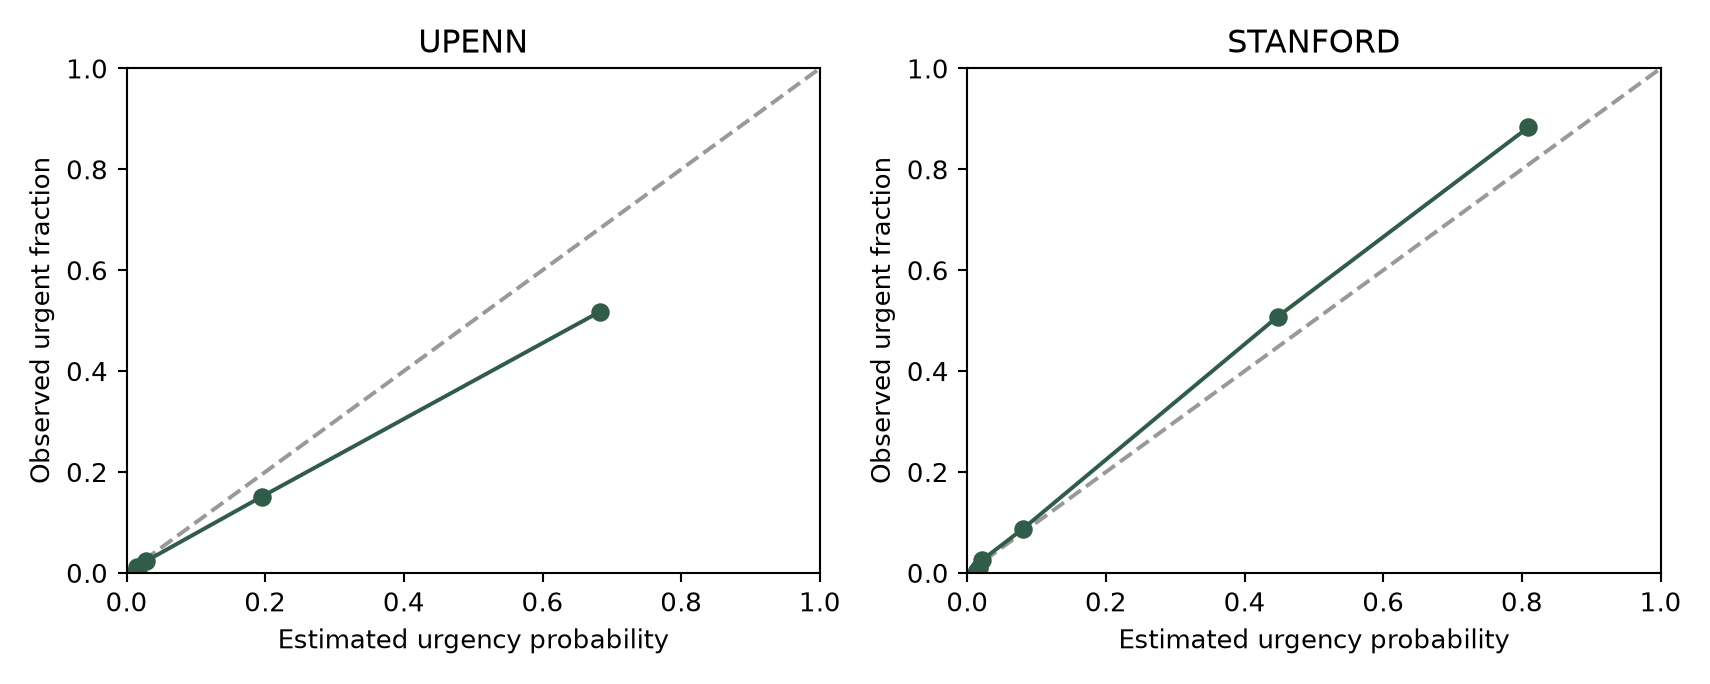

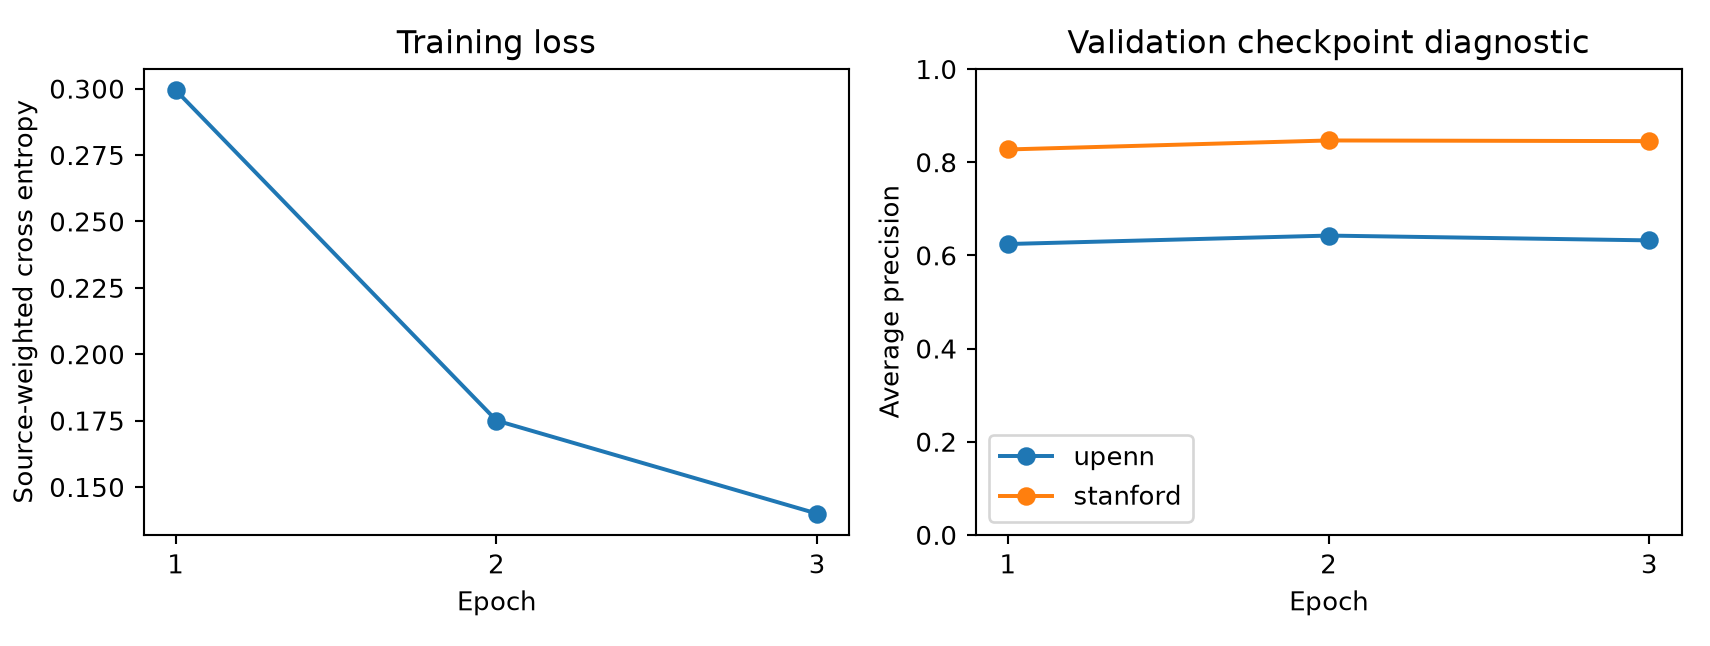

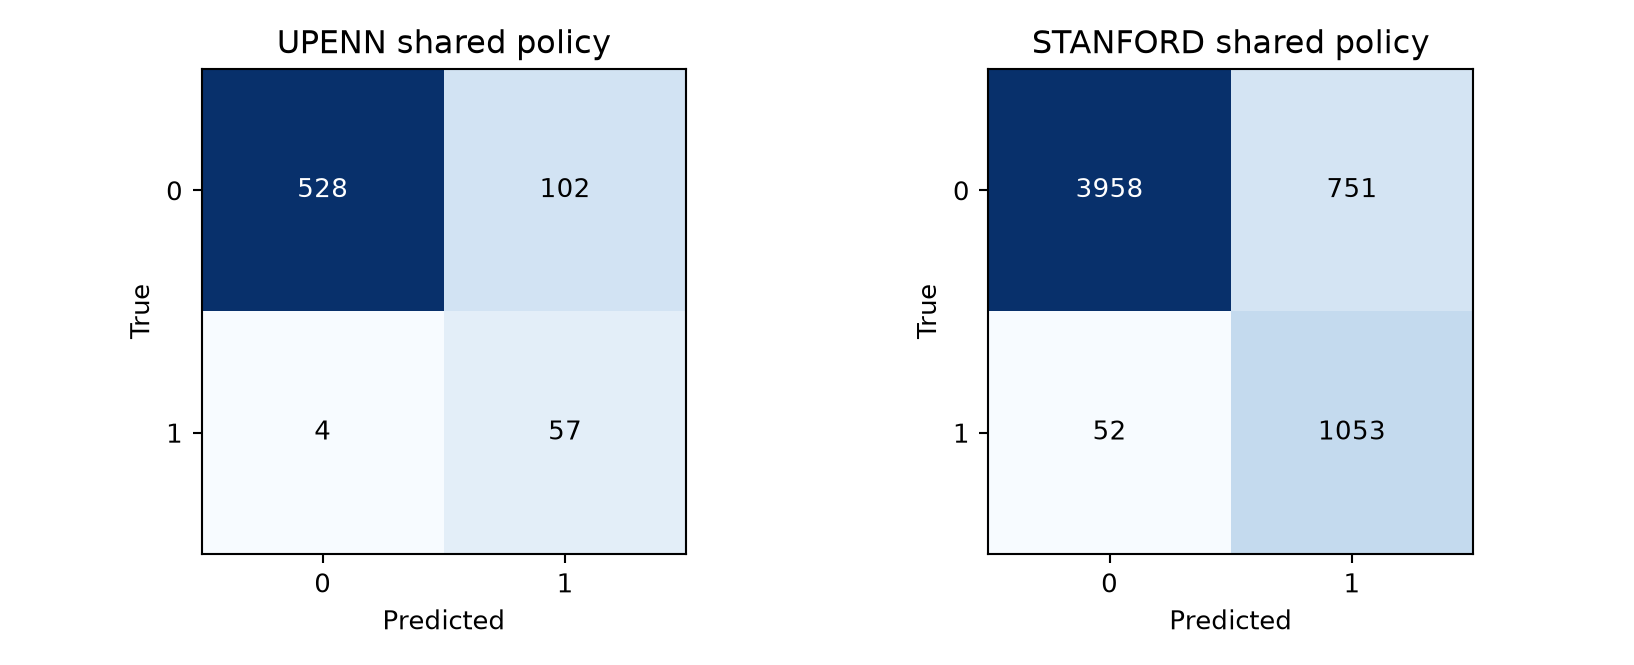

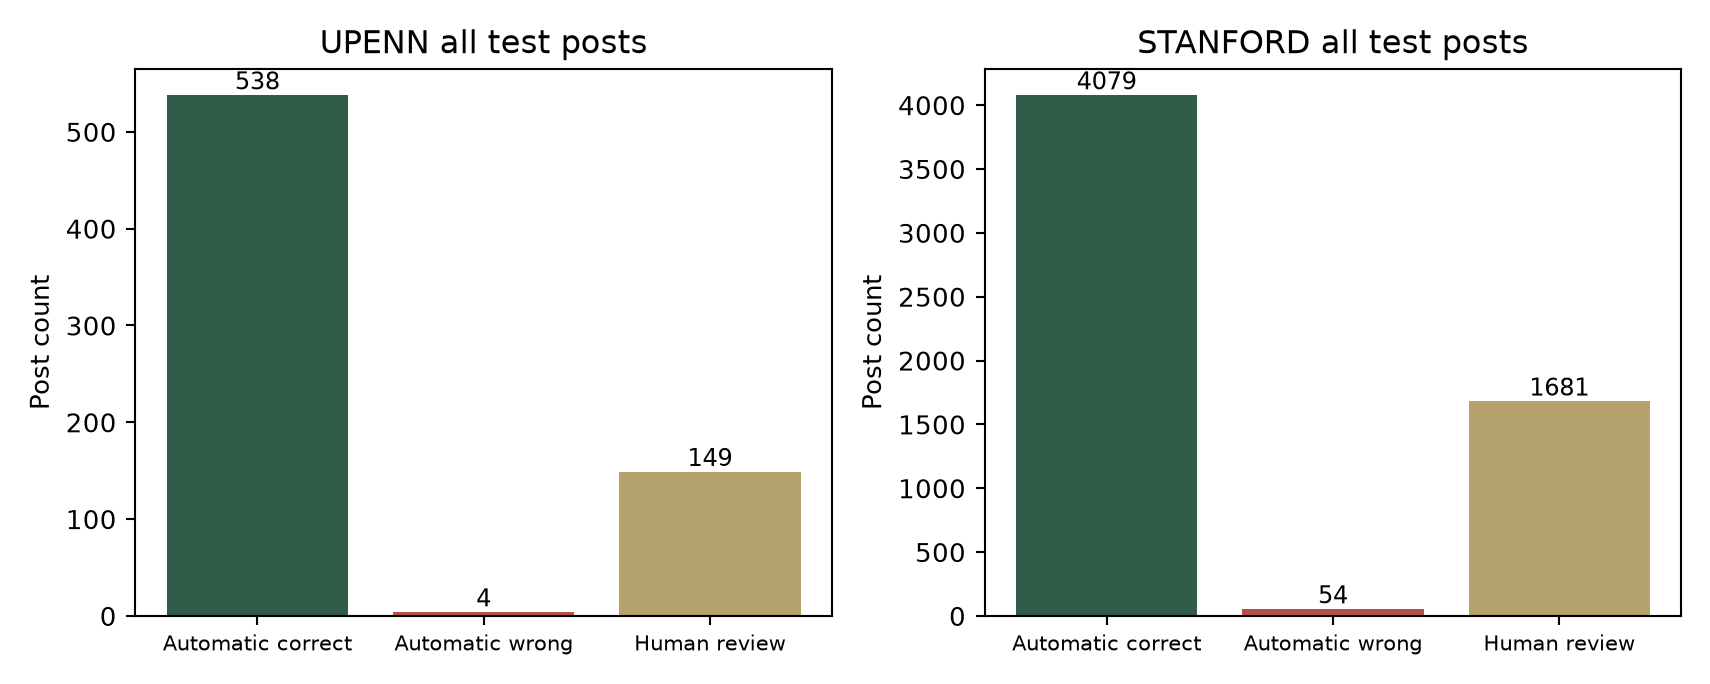

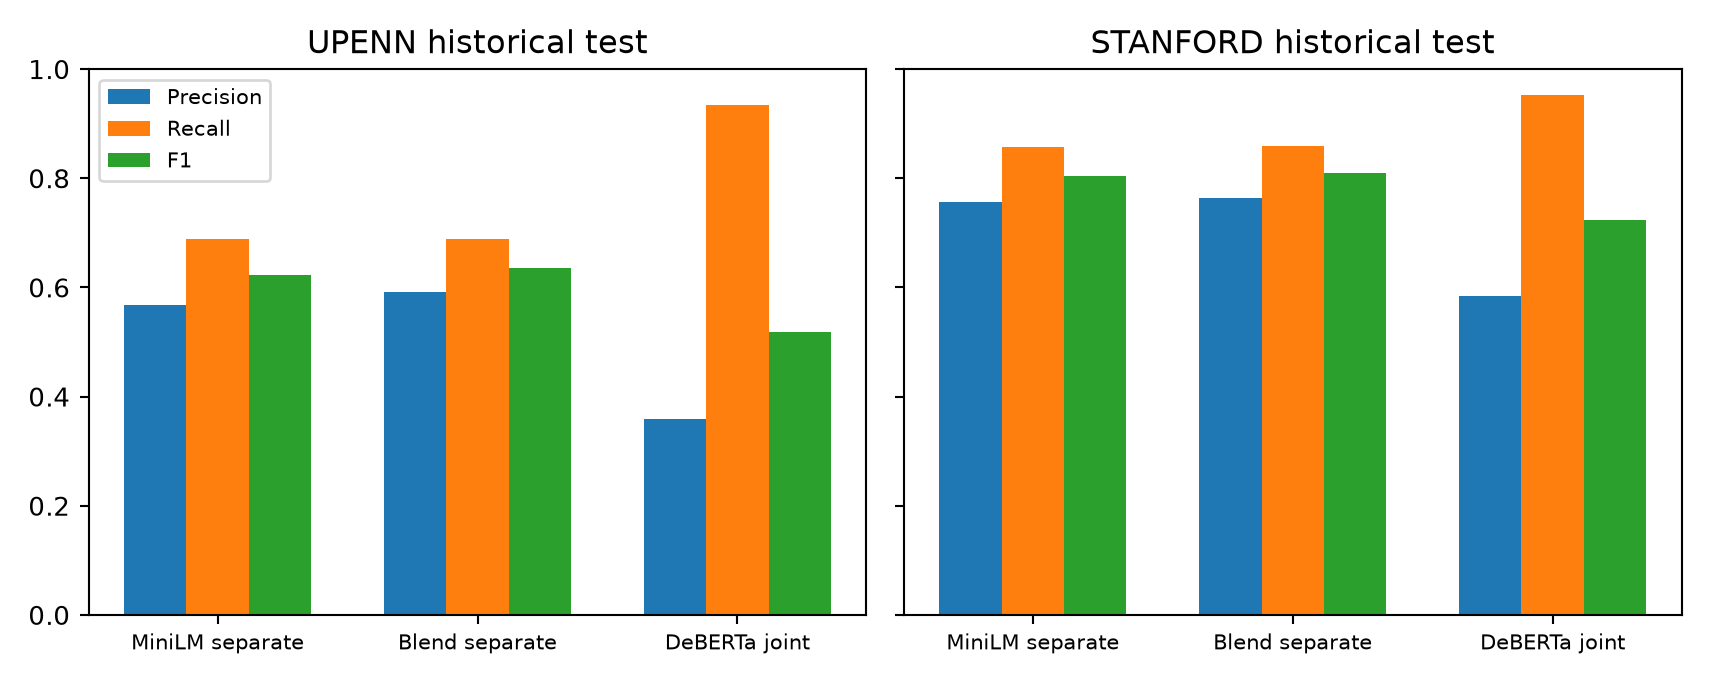

{
  "deberta": {
    "paired_scenarios": 40,
    "score_decreases_after_resolution": 29,
    "interpretation": "Directional behaviour on drafted scenarios, not accuracy or a fresh benchmark."
  },
  "minilm": {
    "paired_scenarios": 40,
    "score_decreases_after_resolution": 34,
    "interpretation": "Directional behaviour on drafted scenarios, not accuracy or a fresh benchmark."
  }
}



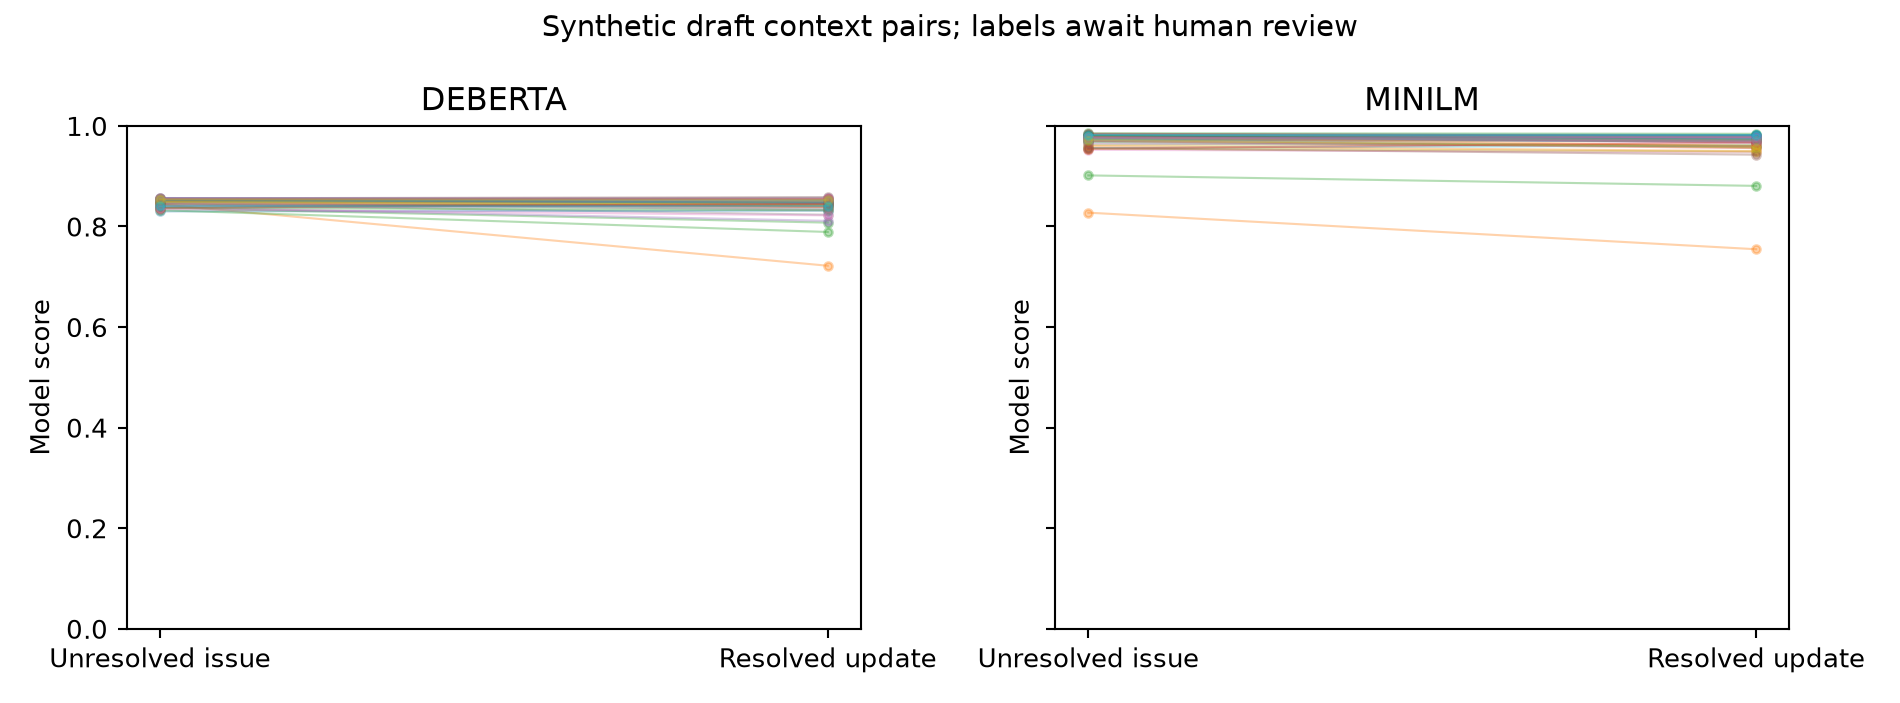

In [16]:
results=json.loads((RUN_DIR/'results.json').read_text())
for row in results:
    print('Policy:',row['policy'],'Test source:',row['test_source'])
    display({k:row[k] for k in ['precision','recall','f1','macro_f1','accuracy','average_precision','roc_auc','brier_score','confusion_matrix','automatic_coverage','automatic_accuracy','review_count']})
print((RUN_DIR/'reliability_audit.json').read_text())
print('Fixed 0.5 diagnostic; deployed policy unchanged:',(RUN_DIR/'fixed_threshold_diagnostic.json').read_text())
import csv
for source in ['upenn','stanford']:
    with (RUN_DIR/f'predictions_{source}_mixed.csv').open(encoding='utf-8',newline='') as f:rows=list(csv.DictReader(f))
    errors=[r for r in rows if r['label']!=r['predicted']]
    errors.sort(key=lambda r:abs(float(r['score'])-.5),reverse=True)
    print(source,'Most confident mistakes; full text retained in the prediction CSV')
    for error in errors[:3]:display(error)
for figure_name in json.loads((RUN_DIR/'figure_files.json').read_text()):display(Image(filename=str(PROJECT/'reports/figures'/figure_name)))
print((RUN_DIR/'custom_context_diagnostics.json').read_text())
context_figure='deberta_context_drafts.png' if RUN_NAME=='deberta_real_only' else 'deberta_reviewed_custom_context_drafts.png'
display(Image(filename=str(PROJECT/'reports/figures'/context_figure)))


## Predict a new post

Change TEXT_TO_PREDICT. The folder includes model weights, tokenizer and calibration policies. REVIEW requires human judgement.


In [17]:
TEXT_TO_PREDICT='I cannot submit my assignment and the deadline is tonight. Please help!'
folder=PROJECT/'models'/('urgency_'+RUN_NAME)
run('predict_reliable_deberta.py','--model',folder,'--text',TEXT_TO_PREDICT)
print((RUN_DIR/'standalone_check.json').read_text())


/Users/nhaterik/lastyear/machine/Project/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


{
  "text": "I cannot submit my assignment and the deadline is tonight. Please help!",
  "score": 0.8382900651426315,
  "raw_score": 0.9445469379425049,
  "threshold": 0.07,
  "binary_priority": 1,
  "action": "REVIEW",
  "domain": "mixed",
  "scope": "English student forum posts",
  "note": "An estimate, not a guarantee of correctness."
}


{
  "passed": true,
  "offline": true,
  "examples": [
    {
      "text": "I cannot submit my assignment and the deadline is tonight. Please help!",
      "score": 0.8382900651426315,
      "raw_score": 0.9445469379425049,
      "threshold": 0.07,
      "binary_priority": 1,
      "action": "REVIEW",
      "domain": "mixed",
      "scope": "English student forum posts",
      "note": "An estimate, not a guarantee of correctness."
    },
    {
      "text": "Thank you for the helpful explanation. I understand now.",
      "score": 0.015066956304246579,
      "raw_score": 0.0006730599561706185,
      "threshold": 0.07,
      "binary_priority": 0,
      "action": "NORMAL",
      "domain": "mixed",
      "scope": "English student forum posts",
      "note": "An estimate, not a guarantee of correctness."
    }
  ]
}



## Download the trained model, three datasets and statistics


In [18]:
from zipfile import ZipFile,ZIP_DEFLATED
archive=PROJECT/'reliable_deberta_and_datasets.zip'
with ZipFile(archive,'w',ZIP_DEFLATED) as z:
    for folder in [PROJECT/'models'/('urgency_'+RUN_NAME),PROJECT/'Datasets',PROJECT/'reports/reliability']:
        for file in folder.rglob('*'):
            if file.is_file() and file.name!='best_state.pt':z.write(file,str(file.relative_to(PROJECT)))
    for figure_name in [*json.loads((RUN_DIR/'figure_files.json').read_text()),context_figure]:z.write(PROJECT/'reports/figures'/figure_name,'reports/figures/'+figure_name)
print('Download:',archive)


Download: /Users/nhaterik/lastyear/machine/Project/reliable_deberta_and_datasets.zip


## Sources and interpretation

- Real datasets and original annotation protocol: https://github.com/pcla-code/forum-posts-urgency
- DeBERTa-v3-base: https://huggingface.co/microsoft/deberta-v3-base
- Calibration: https://scikit-learn.org/stable/modules/calibration.html

The custom dataset is explicitly synthetic and awaits human review. It does not replace fresh independently labelled real-world evaluation.
The new pipeline changes architecture, training composition and calibration together, so differences do not isolate the effect of architecture alone.
